# Representation-Learning Personalization & Cold-Start Recommender (Omnichannel Retail)

Self-contained notebook (no API code). All entities - users, items, stores, sessions, side-information - are projected into one aligned **d = 128** L2-normalised space and four representation learners are compared and fused:

1. Multimodal content-aligned **Two-Tower** (modality / history dropout, InfoNCE)
2. **Inductive heterogeneous GraphSAGE** (User-Item-Brand-Category-Store-Tier-Channel-Quiz graph)
3. **MAML** few-shot user adapter (1-3 clicks)
4. **Self-supervised contrastive** (SimCLR / CL4SRec style) pretraining
5. **Unified router / fusion** + FAISS ANN, stratified offline evaluation (Warm / User / Item / System cold-start)

Sections 1-13 hold the implementation (one cell per component); sections 14+ run the pipeline and show every output.
Run from the repository root.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, time
from pathlib import Path
ROOT = Path.cwd()          # run this notebook from the repository root

## 1. Hardware, mixed precision & seeding

`src/utils/hardware.py`

In [2]:
"""Device detection, mixed precision helpers and seed management."""

import contextlib
import random

import numpy as np
import torch


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_device(pref: str = "auto") -> torch.device:
    if pref != "auto":
        if pref == "cuda" and not torch.cuda.is_available():
            return torch.device("cpu")
        if pref == "mps" and not (hasattr(torch.backends, "mps") and torch.backends.mps.is_available()):
            return torch.device("cpu")
        return torch.device(pref)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def hardware_info(device: torch.device) -> dict:
    info = {"device": str(device), "torch": torch.__version__, "cuda_available": torch.cuda.is_available()}
    if device.type == "cuda":
        info["gpu_name"] = torch.cuda.get_device_name(0)
        info["gpu_mem_gb"] = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    return info


def autocast_ctx(device: torch.device, enabled: bool = True):
    """AMP context: fp16 autocast on CUDA, bf16 on CPU disabled (no-op) for numerical safety."""
    if enabled and device.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()


def make_scaler(device: torch.device, enabled: bool = True):
    return torch.amp.GradScaler("cuda", enabled=bool(enabled and device.type == "cuda"))


## 2. Structured stage logger

`src/utils/logger.py`

In [3]:
"""Structured stage-by-stage logging: console + JSON lines."""

import json
import sys
import time
from contextlib import contextmanager
from pathlib import Path


class StageLogger:
    def __init__(self, path: str | Path = "outputs/logs/pipeline_execution.jsonl", reset: bool = False):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        if reset and self.path.exists():
            self.path.unlink()

    def log(self, stage: str, event: str, **fields) -> None:
        rec = {"ts": time.strftime("%Y-%m-%dT%H:%M:%S"), "stage": stage, "event": event, **fields}
        with open(self.path, "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, default=str) + "\n")
        extra = " ".join(f"{k}={v}" for k, v in fields.items() if not isinstance(v, (dict, list)))
        print(f"[{rec['ts']}] [{stage}] {event} {extra}", file=sys.stdout, flush=True)

    @contextmanager
    def stage(self, name: str, **fields):
        self.log(name, "start", **fields)
        t0 = time.time()
        try:
            yield
        except Exception as e:
            self.log(name, "error", error=repr(e), seconds=round(time.time() - t0, 2))
            raise
        self.log(name, "end", seconds=round(time.time() - t0, 2))


## 3. Synthetic omnichannel data generator with strict cold-start splits

`data/generate_retail_data.py`

In [4]:
"""Synthetic omnichannel retail dataset with strict, leakage-free cold-start splits.

Behaviour is generated from latent user preferences (category / brand / price / region)
that are *observable through side-information* (quiz tags, region, channel, item text,
visual features), so content-based representation learning has real signal to find.

Outputs (data/generated/):
  items.parquet, users.parquet, stores.parquet, interactions.parquet, split_manifest.json
"""

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd


BASE_TS = 1735689600  # 2025-01-01
DAY = 86400
HORIZON_DAYS = 180

TAXONOMY = {
    "Apparel": {
        "Tops": ["T-Shirts", "Shirts", "Sweaters"],
        "Bottoms": ["Jeans", "Chinos", "Shorts"],
        "Outerwear": ["Jackets", "Coats", "Vests"],
    },
    "Footwear": {
        "Casual Shoes": ["Sneakers", "Loafers", "Sandals"],
        "Athletic Shoes": ["Running Shoes", "Training Shoes", "Trail Shoes"],
        "Formal Shoes": ["Oxfords", "Heels", "Boots"],
    },
    "Home": {
        "Kitchen": ["Cookware", "Cutlery", "Appliances"],
        "Bedroom": ["Bedding", "Pillows", "Lamps"],
        "Decor": ["Wall Art", "Rugs", "Candles"],
    },
    "Electronics": {
        "Audio": ["Headphones", "Speakers", "Earbuds"],
        "Mobile": ["Phone Cases", "Chargers", "Power Banks"],
        "Wearables": ["Smartwatches", "Fitness Bands", "Trackers"],
    },
    "Beauty": {
        "Skincare": ["Moisturizers", "Serums", "Sunscreen"],
        "Makeup": ["Lipsticks", "Foundation", "Mascara"],
        "Haircare": ["Shampoo", "Conditioner", "Styling"],
    },
    "Sports": {
        "Fitness": ["Yoga Mats", "Dumbbells", "Resistance Bands"],
        "Outdoor": ["Backpacks", "Tents", "Water Bottles"],
        "Team Sports": ["Footballs", "Basketballs", "Rackets"],
    },
}
COLORS = ["black", "white", "navy", "grey", "red", "green", "beige", "brown", "blue", "pink"]
MATERIALS = ["cotton", "leather", "denim", "wool", "steel", "plastic", "silicone", "ceramic", "mesh", "linen"]
ADJ = ["classic", "premium", "essential", "modern", "lightweight", "durable", "signature", "everyday", "compact", "ergonomic"]
COMMON = ["quality", "design", "comfort", "style", "value", "daily", "perfect", "great", "new", "popular", "season", "gift"]
CHANNELS = ["organic", "paid_search", "in_store_qr", "social"]
LOYALTY = ["none", "bronze", "silver", "gold", "platinum"]
OS = ["ios", "android", "windows", "macos"]
REGIONS = ["north", "south", "east", "west", "central"]
EVENTS = ["view", "add_to_cart", "purchase", "pos_scan"]


def build_taxonomy_table():
    rows = []
    for l1, d in TAXONOMY.items():
        for l2, l3s in d.items():
            for l3 in l3s:
                rows.append((l1, l2, l3))
    return pd.DataFrame(rows, columns=["l1", "l2", "l3"])


def generate(cfg: dict, out_dir: Path, seed: int = 42, verbose: bool = True) -> dict:
    dc = cfg["data"]
    rng = np.random.default_rng(seed)
    nU, nI, nS, nX = dc["n_users"], dc["n_items"], dc["n_stores"], dc["n_interactions"]
    vdim = dc["visual_dim"]
    tax = build_taxonomy_table()
    n_l3, l2_names = len(tax), list(dict.fromkeys(tax.l2))
    l1_names = list(TAXONOMY)

    # ------------------------------------------------------------------ stores
    stores = pd.DataFrame({
        "store_id": [f"S{j:02d}" for j in range(nS)],
        "region": [REGIONS[j % len(REGIONS)] for j in range(nS)],
        "size_sqm": rng.integers(300, 3000, nS),
        "is_urban": rng.integers(0, 2, nS),
    })

    # ------------------------------------------------------------------ items
    l3_idx = rng.choice(n_l3, size=nI, p=rng.dirichlet(np.ones(n_l3) * 6))
    brands = [f"Brand{b:02d}" for b in range(40)]
    brand_l1 = {b: rng.choice(len(l1_names), size=2, replace=False) for b in brands}
    brand_quality = rng.uniform(0, 1, len(brands))
    item_brand = []
    for li in l3_idx:
        l1_i = l1_names.index(tax.l1[li])
        cands = [b for b in brands if l1_i in brand_l1[b]] or brands
        item_brand.append(rng.choice(cands))
    item_brand = np.array(item_brand)
    price_tier = np.clip(np.round(brand_quality[[brands.index(b) for b in item_brand]] * 3 + rng.normal(0, 0.6, nI)).astype(int) + 1, 1, 4)
    price = np.round(np.exp(rng.normal(3.0 + 0.7 * price_tier, 0.25)), 2)
    margin = np.round(rng.beta(2, 5, nI) * 0.6 + 0.1, 3)
    color = rng.choice(COLORS, nI)
    material = rng.choice(MATERIALS, nI)
    launch_day = rng.uniform(0, 100, nI)
    launch_ts = (BASE_TS + launch_day * DAY).astype(np.int64)

    l3_kw = {}
    for li in range(n_l3):
        pool = [tax.l3[li].lower(), tax.l2[li].lower(), tax.l1[li].lower()] + [f"{tax.l3[li][:4].lower()}{k}" for k in range(3)]
        l3_kw[li] = pool
    titles, descs = [], []
    for i in range(nI):
        li = l3_idx[i]
        adj = rng.choice(ADJ)
        titles.append(f"{item_brand[i]} {adj} {color[i]} {tax.l3[li][:-1] if tax.l3[li].endswith('s') else tax.l3[li]}")
        words = list(rng.choice(l3_kw[li], 6)) + list(rng.choice(COMMON, 4)) + [material[i], color[i], adj, tax.l2[li].lower(), tax.l1[li].lower()]
        rng.shuffle(words)
        descs.append(f"{titles[i]}. Made of {material[i]}. " + " ".join(words))

    # visual: hierarchical centroids + brand offset + noise (simulated CLIP/ResNet embedding)
    l1_c = rng.normal(0, 1, (len(l1_names), vdim))
    l2_c = rng.normal(0, 0.7, (len(l2_names), vdim))
    l3_c = rng.normal(0, 0.5, (n_l3, vdim))
    br_c = rng.normal(0, 0.25, (len(brands), vdim))
    vis = np.stack([
        l1_c[l1_names.index(tax.l1[l3_idx[i]])] + l2_c[l2_names.index(tax.l2[l3_idx[i]])] + l3_c[l3_idx[i]]
        + br_c[brands.index(item_brand[i])] + rng.normal(0, 0.6, vdim) for i in range(nI)
    ])
    vis = vis / np.linalg.norm(vis, axis=1, keepdims=True)
    items = pd.DataFrame({
        "item_id": [f"I{i:04d}" for i in range(nI)],
        "title": titles, "description": descs,
        "l1": tax.l1.values[l3_idx], "l2": tax.l2.values[l3_idx], "l3": tax.l3.values[l3_idx],
        "brand": item_brand, "price_tier": price_tier, "price": price, "margin": margin,
        "color": color, "material": material, "launch_ts": launch_ts,
    })
    for d in range(vdim):
        items[f"vis_{d}"] = vis[:, d].astype(np.float32)

    # ------------------------------------------------------------------ cold-start assignments (BEFORE behaviour)
    item_cold = np.zeros(nI, bool)
    item_cold[rng.choice(nI, int(round(dc["item_cold_frac"] * nI)), replace=False)] = True
    items["is_cold_item"] = item_cold

    # ------------------------------------------------------------------ users
    region = rng.choice(REGIONS, nU)
    store_by_region = {r: stores.store_id[stores.region == r].tolist() for r in REGIONS}
    home_store = np.array([rng.choice(store_by_region[r]) for r in region])
    channel = rng.choice(CHANNELS, nU, p=[0.4, 0.25, 0.15, 0.2])
    loyalty = rng.choice(LOYALTY, nU, p=[0.3, 0.25, 0.2, 0.15, 0.1])
    os_ = rng.choice(OS, nU, p=[0.4, 0.4, 0.1, 0.1])

    aff_l2 = rng.dirichlet(np.ones(len(l2_names)) * 0.25, nU)
    reg_boost = rng.dirichlet(np.ones(len(l2_names)) * 2.0, len(REGIONS))
    aff_l2 = aff_l2 * 0.85 + 0.15 * reg_boost[[REGIONS.index(r) for r in region]]
    aff_l2 /= aff_l2.sum(1, keepdims=True)
    brand_pref = rng.dirichlet(np.ones(len(brands)) * 0.6, nU)
    tier_pref = np.clip(rng.normal(2.2 + 0.25 * np.array([LOYALTY.index(x) for x in loyalty]), 0.7), 1, 4)

    quiz_vocab = [f"likes_{n.lower().replace(' ', '_')}" for n in l2_names] + [f"cat_{n.lower()}" for n in l1_names]
    quiz = []
    for u in range(nU):
        k = rng.integers(1, 4)
        top = np.argsort(-aff_l2[u])[:k]
        tags = []
        for t in top:
            if rng.random() < 0.8:
                tags.append(quiz_vocab[t])
            else:
                tags.append(quiz_vocab[rng.integers(len(quiz_vocab))])
        quiz.append("|".join(sorted(set(tags))))

    # system cold-start: entire stores withheld => their users are zero-shot and have never been served
    sys_stores = list(rng.choice(stores.store_id, dc["system_cold_stores"], replace=False))
    sys_user = np.isin(home_store, sys_stores)
    other = np.where(~sys_user)[0]
    cold_users = rng.choice(other, int(round(dc["user_cold_frac"] * nU)), replace=False)
    zero_cnt = int(round(len(cold_users) * dc["zero_shot_user_share"]))
    group = np.array(["warm"] * nU, dtype=object)
    group[cold_users[:zero_cnt]] = "zero_shot"
    group[cold_users[zero_cnt:]] = "few_shot"
    group[sys_user] = "system_cold"
    users = pd.DataFrame({
        "user_id": [f"U{u:04d}" for u in range(nU)],
        "acquisition_channel": channel, "loyalty_tier": loyalty, "home_region": region,
        "home_store": home_store, "device_os": os_, "quiz_tags": quiz, "user_group": group,
    })
    stores["is_system_cold"] = stores.store_id.isin(sys_stores)

    # ------------------------------------------------------------------ behaviour
    pop = rng.zipf(1.6, nI).astype(float)
    pop = np.clip(pop, 1, 60)
    log_pop = np.log(pop)
    l2_of_item = np.array([l2_names.index(x) for x in items.l2])
    brand_of_item = np.array([brands.index(b) for b in item_brand])
    score = (
        0.4 * log_pop[None, :]
        + 2.2 * np.log(aff_l2[:, l2_of_item] + 1e-3)
        + 1.0 * np.log(brand_pref[:, brand_of_item] + 1e-3)
        - 0.8 * np.abs(tier_pref[:, None] - price_tier[None, :])
    )
    activity = 3 + rng.negative_binomial(2, 2 / (2 + (nX / nU - 3)), nU)
    activity = np.maximum(3, np.round(activity * nX / activity.sum())).astype(int)
    rows = []
    for u in range(nU):
        n = int(activity[u])
        ts = np.sort(BASE_TS + rng.uniform(0, HORIZON_DAYS, n) * DAY)
        s_u = score[u].copy()
        if group[u] == "system_cold":
            s_u[item_cold] += np.log(3.0)   # new-store launch pushes newly launched items
        # session structure: every 1-3 consecutive events share a session / visit day
        sess = 0
        sess_of = np.zeros(n, int)
        for k in range(1, n):
            if rng.random() < 0.45 and ts[k] - ts[k - 1] < DAY:
                sess_of[k] = sess_of[k - 1]
            else:
                sess += 1
                sess_of[k] = sess
        # users drift slightly inside a session: session intent amplifies one category
        for k in range(n):
            avail = launch_ts <= ts[k]
            if not avail.any():
                avail[:] = True
            p = np.exp(s_u - s_u[avail].max()) * avail
            p /= p.sum()
            it = rng.choice(nI, p=p)
            instore = rng.random() < (0.35 if channel[u] == "in_store_qr" else 0.15)
            if instore:
                ev, ch = ("pos_scan" if rng.random() < 0.7 else "view"), "store"
            else:
                ev = rng.choice(["view", "add_to_cart", "purchase"], p=[0.65, 0.2, 0.15])
                ch = "app" if os_[u] in ("ios", "android") and rng.random() < 0.7 else "web"
            st = home_store[u] if (ch == "store" or rng.random() < 0.6) else rng.choice(stores.store_id)
            hr = int((ts[k] % DAY) // 3600)
            rows.append((users.user_id[u], items.item_id[it], ev, ch, st, f"{users.user_id[u]}_S{sess_of[k]}", int(ts[k]), hr,
                         os_[u] if ch != "store" else "pos"))
    inter = pd.DataFrame(rows, columns=["user_id", "item_id", "event_type", "channel", "store_id", "session_id", "ts", "hour", "device"])
    inter = inter.sort_values("ts").reset_index(drop=True)

    # ------------------------------------------------------------------ splits
    inter["user_group"] = inter.user_id.map(users.set_index("user_id").user_group)
    inter["item_cold"] = inter.item_id.map(items.set_index("item_id").is_cold_item)
    t_val = BASE_TS + int(0.70 * HORIZON_DAYS) * DAY
    t_test = BASE_TS + int(0.85 * HORIZON_DAYS) * DAY
    split = np.full(len(inter), "drop", dtype=object)
    slice_ = np.full(len(inter), "", dtype=object)

    g = inter.user_group.values
    ic = inter.item_cold.values
    ts_ = inter.ts.values
    rank_in_user = inter.groupby("user_id").cumcount().values      # chronological rank (sorted by ts)
    nU_total = inter.groupby("user_id").user_id.transform("size").values

    # warm users: global temporal cut
    w = g == "warm"
    split[w & ~ic & (ts_ < t_val)] = "train"
    ev = w & (ts_ >= t_val)
    split[ev & (ts_ < t_test)] = "val"
    split[ev & (ts_ >= t_test)] = "test"
    slice_[ev & ~ic] = "warm"
    slice_[ev & ic] = "item_cold"
    # few-shot: first k (1..3) *warm-item* interactions go to train, rest to eval
    k_user = pd.Series(rng.integers(1, 4, nU), index=users.user_id)
    fs = g == "few_shot"
    kk = inter.user_id.map(k_user).values
    cum_warm = (fs & ~ic).astype(int)
    cum_warm = pd.Series(cum_warm).groupby(inter.user_id.values).cumsum().values
    is_hist = fs & ~ic & (cum_warm <= kk)
    split[is_hist] = "train"
    rest = fs & ~is_hist
    # eval items for few-shot / zero-shot / system users: chronological split by per-user median
    def half_split(mask):
        idx = np.where(mask)[0]
        df = pd.DataFrame({"u": inter.user_id.values[idx], "r": np.arange(len(idx))})
        df["rk"] = df.groupby("u").cumcount()
        df["n"] = df.groupby("u").u.transform("size")
        return idx, (df.rk.values < np.ceil(df.n.values / 2)), df
    for m in (rest, g == "zero_shot", g == "system_cold"):
        idx, first_half, _ = half_split(m)
        split[idx] = np.where(first_half, "val", "test")
    uc = (fs & ~is_hist) | (g == "zero_shot")
    slice_[uc & ~ic] = "user_cold"
    # user-cold x item-cold and few-shot/zero-shot with cold items are not an official slice
    split[uc & ic] = np.where(split[uc & ic] == "train", "train", split[uc & ic])
    slice_[uc & ic] = "user_item_cold_unassigned"
    sysm = g == "system_cold"
    slice_[sysm & ic] = "system_cold"
    slice_[sysm & ~ic] = "system_user_warm_item_unassigned"
    inter["split"] = split
    inter["slice"] = slice_
    inter = inter.drop(columns=["user_group", "item_cold"])

    # warm users with zero train interactions cannot be "warm": drop their eval rows
    ntr = inter[inter.split == "train"].groupby("user_id").size()
    users["n_train_interactions"] = users.user_id.map(ntr).fillna(0).astype(int)
    bad = users.user_id[(users.user_group == "warm") & (users.n_train_interactions == 0)]
    inter.loc[inter.user_id.isin(bad) & (inter.split != "train"), "split"] = "drop"

    # ------------------------------------------------------------------ leakage assertions
    tr = inter[inter.split == "train"]
    assert not tr.item_id.isin(items.item_id[items.is_cold_item]).any(), "cold item leaked into train"
    assert not tr.user_id.isin(users.user_id[users.user_group.isin(["zero_shot", "system_cold"])]).any(), "zero-shot user leaked"
    assert not tr.user_id.isin(users.user_id[users.user_group == "system_cold"]).any()
    fs_cnt = tr[tr.user_id.isin(users.user_id[users.user_group == "few_shot"])].groupby("user_id").size()
    assert fs_cnt.max() <= 3, "few-shot user has >3 train interactions"
    # temporal sanity for warm users
    assert tr[tr.user_id.isin(users.user_id[users.user_group == "warm"])].ts.max() < t_val
    ev_df = inter[inter.split.isin(["val", "test"]) & inter["slice"].isin(["warm", "item_cold", "user_cold", "system_cold"])]
    manifest = {
        "n_users": nU, "n_items": nI, "n_stores": nS, "n_interactions": int(len(inter)),
        "train_rows": int((inter.split == "train").sum()),
        "val_rows": int((inter.split == "val").sum()), "test_rows": int((inter.split == "test").sum()),
        "slices": {s: {sp: int(((ev_df["slice"] == s) & (ev_df.split == sp)).sum()) for sp in ("val", "test")}
                   for s in ["warm", "item_cold", "user_cold", "system_cold"]},
        "user_groups": users.user_group.value_counts().to_dict(),
        "cold_items": int(items.is_cold_item.sum()),
        "system_cold_stores": sys_stores,
        "t_val": int(t_val), "t_test": int(t_test),
        "leakage_checks": "passed",
    }
    out_dir.mkdir(parents=True, exist_ok=True)
    items.to_parquet(out_dir / "items.parquet")
    users.to_parquet(out_dir / "users.parquet")
    stores.to_parquet(out_dir / "stores.parquet")
    inter.to_parquet(out_dir / "interactions.parquet")
    json.dump(manifest, open(out_dir / "split_manifest.json", "w"), indent=2)
    if verbose:
        print(json.dumps(manifest, indent=2))
    return manifest


## 4. Representation encoders (text TF-IDF/SVD, visual, tabular, temporal)

`src/features/representation_encoders.py`

In [5]:
"""Text (TF-IDF -> SVD), visual, tabular and temporal encoders.

All statistics (vocabularies, TF-IDF, scalers) are fitted on TRAIN-visible entities only:
  * text / vocab / scaler fit on warm (non cold) items
  * user vocab on users that appear in train
Unseen categorical values map to a reserved UNK index (0), which makes the encoders usable
for zero-shot items / users / stores at serving time.
"""

import pickle
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

ITEM_CAT_COLS = ["l1", "l2", "l3", "brand", "price_tier", "color", "material"]
USER_CAT_COLS = ["acquisition_channel", "loyalty_tier", "home_region", "home_store", "device_os"]
CTX_CAT_COLS = ["device", "store_id", "channel"]
BASE_TS = 1735689600
DAY = 86400
HORIZON = 180 * DAY


@dataclass
class Features:
    item_ids: list
    user_ids: list
    item_cat: np.ndarray        # (nI, 7) int64
    item_cont: np.ndarray       # (nI, 3) float32
    item_text: np.ndarray       # (nI, text_dim)
    item_vis: np.ndarray        # (nI, vis_dim)
    user_cat: np.ndarray        # (nU, 5) int64
    user_quiz: np.ndarray       # (nU, n_quiz) float32
    item_cold: np.ndarray       # (nI,) bool
    user_group: np.ndarray      # (nU,) object
    item_l3: np.ndarray
    item_l2: np.ndarray
    item_l1: np.ndarray
    item_brand: np.ndarray
    item_tier: np.ndarray
    cat_sizes: dict = field(default_factory=dict)


class RepresentationEncoders:
    """Fit / transform wrapper. `transform_*` accept raw dict records (used by the serving layer)."""

    def __init__(self, text_dim: int = 64, tfidf_max_features: int = 4000, vis_dim: int = 64, seed: int = 42):
        self.text_dim, self.vis_dim, self.seed = text_dim, vis_dim, seed
        self.tfidf = TfidfVectorizer(max_features=tfidf_max_features, ngram_range=(1, 2), sublinear_tf=True, min_df=2)
        self.svd = TruncatedSVD(n_components=text_dim, random_state=seed)
        self.vocab: dict[str, dict] = {}
        self.quiz_vocab: list[str] = []
        self.cont_stats: dict = {}
        self.text_scale = 1.0

    # ------------------------------------------------------------------ fit
    @staticmethod
    def _build_vocab(values) -> dict:
        vocab = {"<UNK>": 0}
        for v in sorted(set(map(str, values))):
            vocab[v] = len(vocab)
        return vocab

    def fit(self, items: pd.DataFrame, users: pd.DataFrame, stores: pd.DataFrame, inter: pd.DataFrame) -> "RepresentationEncoders":
        warm_items = items[~items.is_cold_item]
        for c in ITEM_CAT_COLS:
            self.vocab[c] = self._build_vocab(warm_items[c])
        train_users = set(inter.loc[inter.split == "train", "user_id"])
        tu = users[users.user_id.isin(train_users)]
        for c in USER_CAT_COLS:
            self.vocab[c] = self._build_vocab(tu[c])
        # contextual vocab from training interactions
        tr = inter[inter.split == "train"]
        self.vocab["device"] = self._build_vocab(tr.device)
        self.vocab["store_id"] = self._build_vocab(tr.store_id)
        self.vocab["channel"] = self._build_vocab(tr.channel)
        tags = sorted({t for q in users.quiz_tags for t in q.split("|")})  # fixed questionnaire vocabulary
        self.quiz_vocab = tags
        text = (warm_items.title + " " + warm_items.description).tolist()
        X = self.tfidf.fit_transform(text)
        Z = self.svd.fit_transform(X)
        self.text_scale = float(np.linalg.norm(Z, axis=1).mean() + 1e-8)
        lp = np.log1p(warm_items.price.values)
        self.cont_stats = {"logp_mean": float(lp.mean()), "logp_std": float(lp.std() + 1e-6),
                           "m_mean": float(warm_items.margin.mean()), "m_std": float(warm_items.margin.std() + 1e-6)}
        self.stores = stores.set_index("store_id")
        return self

    # ------------------------------------------------------------------ transform
    def _cat(self, col: str, values) -> np.ndarray:
        v = self.vocab[col]
        return np.array([v.get(str(x), 0) for x in values], dtype=np.int64)

    def text_embed(self, titles, descs) -> np.ndarray:
        X = self.tfidf.transform([f"{t} {d}" for t, d in zip(titles, descs)])
        return (self.svd.transform(X) / self.text_scale).astype(np.float32)

    def transform_items(self, df: pd.DataFrame, vis: np.ndarray | None = None) -> dict:
        cat = np.stack([self._cat(c, df[c]) for c in ITEM_CAT_COLS], 1)
        s = self.cont_stats
        launch = ((df.launch_ts.values - BASE_TS) / HORIZON).astype(np.float32) if "launch_ts" in df else np.zeros(len(df), np.float32)
        cont = np.stack([(np.log1p(df.price.values) - s["logp_mean"]) / s["logp_std"],
                         (df.margin.values - s["m_mean"]) / s["m_std"], launch], 1).astype(np.float32)
        if vis is None:
            vis = df[[f"vis_{d}" for d in range(self.vis_dim)]].values.astype(np.float32)
        return {"cat": cat, "cont": cont, "text": self.text_embed(df.title, df.description), "vis": vis.astype(np.float32)}

    def transform_users(self, df: pd.DataFrame) -> dict:
        cat = np.stack([self._cat(c, df[c]) for c in USER_CAT_COLS], 1)
        q = np.zeros((len(df), len(self.quiz_vocab)), np.float32)
        idx = {t: i for i, t in enumerate(self.quiz_vocab)}
        for r, tags in enumerate(df.quiz_tags):
            for t in str(tags).split("|"):
                if t in idx:
                    q[r, idx[t]] = 1.0
        return {"cat": cat, "quiz": q}

    def transform_context(self, hour, device, store_id, channel) -> dict:
        hour = np.asarray(hour, dtype=np.float32)
        tod = np.stack([np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)], 1).astype(np.float32)
        cat = np.stack([self._cat("device", device), self._cat("store_id", store_id), self._cat("channel", channel)], 1)
        return {"cat": cat, "tod": tod}

    def cat_sizes(self) -> dict:
        return {k: len(v) for k, v in self.vocab.items()}

    def build_features(self, items: pd.DataFrame, users: pd.DataFrame) -> Features:
        it = self.transform_items(items)
        us = self.transform_users(users)
        return Features(
            item_ids=items.item_id.tolist(), user_ids=users.user_id.tolist(),
            item_cat=it["cat"], item_cont=it["cont"], item_text=it["text"], item_vis=it["vis"],
            user_cat=us["cat"], user_quiz=us["quiz"],
            item_cold=items.is_cold_item.values.astype(bool), user_group=users.user_group.values,
            item_l3=items.l3.values, item_l2=items.l2.values, item_l1=items.l1.values,
            item_brand=items.brand.values, item_tier=items.price_tier.values, cat_sizes=self.cat_sizes(),
        )

    # ------------------------------------------------------------------ persistence
    def save(self, path: str | Path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump(self, f)

    @staticmethod
    def load(path: str | Path) -> "RepresentationEncoders":
        with open(path, "rb") as f:
            return pickle.load(f)


def load_data(data_dir: str | Path):
    d = Path(data_dir)
    return (pd.read_parquet(d / "items.parquet"), pd.read_parquet(d / "users.parquet"),
            pd.read_parquet(d / "stores.parquet"), pd.read_parquet(d / "interactions.parquet"))


## 5. Shared building blocks (GRN, InfoNCE, NT-Xent, bundle builder)

`src/models/common.py`

In [6]:
"""Shared building blocks: tensors on device, interaction tensors, history matrix, GRN, losses."""

import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F


def l2n(x: torch.Tensor, dim: int = -1) -> torch.Tensor:
    return F.normalize(x, dim=dim, eps=1e-8)


class GRN(nn.Module):
    """Gated Residual Network (Lim et al. 2021): LN(skip(x) + GLU(W2 ELU(W1 x)))."""

    def __init__(self, d_in: int, d_out: int, d_hidden: int | None = None, dropout: float = 0.1):
        super().__init__()
        d_hidden = d_hidden or d_out
        self.fc1 = nn.Linear(d_in, d_hidden)
        self.fc2 = nn.Linear(d_hidden, d_out * 2)
        self.skip = nn.Linear(d_in, d_out) if d_in != d_out else nn.Identity()
        self.drop = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(d_out)

    def forward(self, x):
        h = self.fc2(self.drop(F.elu(self.fc1(x))))
        a, b = h.chunk(2, dim=-1)
        return self.norm(self.skip(x) + a * torch.sigmoid(b))


@dataclass
class FeatureTensors:
    item_cat: torch.Tensor
    item_cont: torch.Tensor
    item_text: torch.Tensor
    item_vis: torch.Tensor
    user_cat: torch.Tensor
    user_quiz: torch.Tensor
    item_cold: torch.Tensor

    @staticmethod
    def from_features(f, device) -> "FeatureTensors":
        t = lambda a, dt=None: torch.as_tensor(a, dtype=dt).to(device)
        return FeatureTensors(t(f.item_cat, torch.long), t(f.item_cont), t(f.item_text), t(f.item_vis),
                              t(f.user_cat, torch.long), t(f.user_quiz), t(f.item_cold, torch.bool))


@dataclass
class InteractionTensors:
    u: torch.Tensor
    i: torch.Tensor
    tod: torch.Tensor        # (N,2)
    ctx_cat: torch.Tensor    # (N,3) device, store, channel
    ts: np.ndarray
    slice: np.ndarray

    def __len__(self):
        return len(self.u)


def build_interactions(df: pd.DataFrame, enc, user_index: dict, item_index: dict, device) -> InteractionTensors:
    ctx = enc.transform_context(df.hour.values, df.device.values, df.store_id.values, df.channel.values)
    return InteractionTensors(
        u=torch.as_tensor(df.user_id.map(user_index).values, dtype=torch.long, device=device),
        i=torch.as_tensor(df.item_id.map(item_index).values, dtype=torch.long, device=device),
        tod=torch.as_tensor(ctx["tod"], device=device),
        ctx_cat=torch.as_tensor(ctx["cat"], dtype=torch.long, device=device),
        ts=df.ts.values, slice=df["slice"].values,
    )


def build_history(train_df: pd.DataFrame, user_index: dict, item_index: dict, n_users: int, max_hist: int) -> np.ndarray:
    """(n_users, H) of item_idx+1, most-recent-last, 0 = pad. Train interactions only (no leakage)."""
    H = np.zeros((n_users, max_hist), dtype=np.int64)
    d = train_df.sort_values("ts")
    for uid, g in d.groupby("user_id"):
        it = g.item_id.map(item_index).values[-max_hist:] + 1
        H[user_index[uid], -len(it):] = it
    return H


def info_nce(q: torch.Tensor, k: torch.Tensor, tau, pos_ids=None, log_q=None) -> torch.Tensor:
    """In-batch InfoNCE; q,k L2-normalised (B,d). Duplicate positives in batch are masked out;
    optional logQ correction removes popularity bias of in-batch negatives."""
    with torch.autocast(device_type=q.device.type, enabled=False):
        logits = (q.float() @ k.float().T) / tau
        if log_q is not None:
            logits = logits - log_q[None, :].float()
        if pos_ids is not None:
            dup = (pos_ids[:, None] == pos_ids[None, :]) & ~torch.eye(len(pos_ids), dtype=torch.bool, device=q.device)
            logits = logits.masked_fill(dup, -1e9)
        return F.cross_entropy(logits, torch.arange(len(q), device=q.device))


def nt_xent(z1: torch.Tensor, z2: torch.Tensor, tau: float) -> torch.Tensor:
    """SimCLR NT-Xent over 2B views."""
    B = z1.shape[0]
    with torch.autocast(device_type=z1.device.type, enabled=False):
        z = l2n(torch.cat([z1, z2], 0).float())
        sim = z @ z.T / tau
        sim = sim.masked_fill(torch.eye(2 * B, dtype=torch.bool, device=z.device), -1e9)
        tgt = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)
        return F.cross_entropy(sim, tgt)


def uniformity(x: torch.Tensor, t: float = 2.0, max_n: int = 2000) -> float:
    x = l2n(x.float())
    if len(x) > max_n:
        x = x[torch.randperm(len(x), device=x.device)[:max_n]]
    sq = torch.pdist(x, p=2).pow(2)
    return float(torch.log(torch.exp(-t * sq).mean() + 1e-12))


def alignment(a: torch.Tensor, b: torch.Tensor, alpha: int = 2) -> float:
    return float((l2n(a.float()) - l2n(b.float())).norm(dim=1).pow(alpha).mean())


def scaled_epochs(n: int, quick: bool, scale: float) -> int:
    return max(2, int(math.ceil(n * scale))) if quick else n


SLICES = ["warm", "user_cold", "item_cold", "system_cold"]


@dataclass
class Bundle:
    cfg: dict
    device: torch.device
    items: pd.DataFrame
    users: pd.DataFrame
    stores: pd.DataFrame
    inter: pd.DataFrame
    enc: object
    feats: object
    ft: FeatureTensors
    user_index: dict
    item_index: dict
    tr_df: pd.DataFrame
    val_df: pd.DataFrame
    test_df: pd.DataFrame
    tr: InteractionTensors
    va: InteractionTensors
    hist: torch.Tensor
    hist_np: np.ndarray
    item_logq: torch.Tensor
    cat_sizes: dict
    text_dim: int
    vis_dim: int
    n_quiz: int

    @property
    def n_items(self):
        return len(self.items)

    @property
    def n_users(self):
        return len(self.users)


def build_bundle(cfg: dict, root, device) -> Bundle:
    from pathlib import Path
    root = Path(root)
    items, users, stores, inter = load_data(root / cfg["paths"]["data_dir"])
    enc = RepresentationEncoders(cfg["features"]["text_svd_dim"], cfg["features"]["tfidf_max_features"], cfg["data"]["visual_dim"], cfg["seed"])
    enc.fit(items, users, stores, inter)
    feats = enc.build_features(items, users)
    ft = FeatureTensors.from_features(feats, device)
    ui = {u: k for k, u in enumerate(users.user_id)}
    ii = {i: k for k, i in enumerate(items.item_id)}
    tr_df = inter[inter.split == "train"].reset_index(drop=True)
    official = inter["slice"].isin(SLICES)
    val_df = inter[(inter.split == "val") & official].reset_index(drop=True)
    test_df = inter[(inter.split == "test") & official].reset_index(drop=True)
    hist_np = build_history(tr_df, ui, ii, len(users), cfg["train"]["two_tower"]["max_history"])
    cnt = np.bincount(tr_df.item_id.map(ii).values, minlength=len(items)).astype(np.float64) + 1.0
    logq = torch.as_tensor(np.log(cnt / cnt.sum()), dtype=torch.float32, device=device)
    return Bundle(cfg, device, items, users, stores, inter, enc, feats, ft, ui, ii, tr_df, val_df, test_df,
                  build_interactions(tr_df, enc, ui, ii, device), build_interactions(val_df, enc, ui, ii, device),
                  torch.as_tensor(hist_np, device=device), hist_np, logq, enc.cat_sizes(), enc.text_dim, enc.vis_dim, len(enc.quiz_vocab))


## 6. Approach 1: Multimodal content-aligned two-tower

`src/models/multimodal_two_tower.py`

In [7]:
"""Approach 1: Content-aligned multimodal two-tower with modality / history dropout.

Item tower  : categorical-attribute embeddings + continuous attrs + text (TF-IDF/SVD) + visual (CLIP-like)
              fused by a Gated Residual Network. Missing modalities are replaced by learned 'missing' vectors.
User tower  : static profile (categorical + quiz tags) + context (time-of-day, device, store, channel)
              + masked-mean pooled interaction history (item-tower embeddings of previously seen items).
Cold-start  : history dropout (p=0.3) zeroes the history branch during training so the user tower must
              align profile/context directly with the item *content* tower through InfoNCE.
"""

import time

import torch
import torch.nn as nn
import torch.nn.functional as F


ITEM_CATS = ["l1", "l2", "l3", "brand", "price_tier", "color", "material"]
USER_CATS = ["acquisition_channel", "loyalty_tier", "home_region", "home_store", "device_os"]
CTX_CATS = ["device", "store_id", "channel"]


class ItemTower(nn.Module):
    def __init__(self, cat_sizes: dict, text_dim: int, vis_dim: int, d: int = 128, emb: int = 16, dropout: float = 0.1):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(cat_sizes[c], emb) for c in ITEM_CATS])
        self.attr = nn.Sequential(nn.Linear(emb * len(ITEM_CATS) + 3, d), nn.ReLU())
        self.text = nn.Sequential(nn.Linear(text_dim, d), nn.ReLU())
        self.vis = nn.Sequential(nn.Linear(vis_dim, d), nn.ReLU())
        self.miss_text = nn.Parameter(torch.zeros(d))
        self.miss_vis = nn.Parameter(torch.zeros(d))
        self.fuse = GRN(3 * d, d, d_hidden=2 * d, dropout=dropout)
        self.out = nn.Linear(d, d)

    def forward(self, cat, cont, text, vis, miss_text=None, miss_vis=None):
        a = self.attr(torch.cat([e(cat[:, k]) for k, e in enumerate(self.embs)] + [cont], -1))
        t, v = self.text(text), self.vis(vis)
        if miss_text is not None:
            t = torch.where(miss_text[:, None], self.miss_text.expand_as(t), t)
        if miss_vis is not None:
            v = torch.where(miss_vis[:, None], self.miss_vis.expand_as(v), v)
        return l2n(self.out(self.fuse(torch.cat([a, t, v], -1))))


class UserTower(nn.Module):
    def __init__(self, cat_sizes: dict, n_quiz: int, d: int = 128, emb: int = 16, dropout: float = 0.1):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(cat_sizes[c], emb) for c in USER_CATS])
        self.quiz = nn.Sequential(nn.Linear(n_quiz, 64), nn.ReLU())
        self.ctx_embs = nn.ModuleList([nn.Embedding(cat_sizes[c], emb) for c in CTX_CATS])
        self.hist_proj = nn.Linear(d, d)
        d_in = emb * len(USER_CATS) + 64 + emb * len(CTX_CATS) + 2 + d + 1
        self.fuse = GRN(d_in, d, d_hidden=2 * d, dropout=dropout)
        self.out = nn.Linear(d, d)

    def forward(self, ucat, quiz, ctx_cat, tod, hist_pooled, has_hist):
        x = torch.cat([e(ucat[:, k]) for k, e in enumerate(self.embs)] + [self.quiz(quiz)]
                      + [e(ctx_cat[:, k]) for k, e in enumerate(self.ctx_embs)] + [tod]
                      + [self.hist_proj(hist_pooled) * has_hist[:, None], has_hist[:, None]], -1)
        return l2n(self.out(self.fuse(x)))


class MultimodalTwoTower(nn.Module):
    def __init__(self, cat_sizes, text_dim, vis_dim, n_quiz, d=128, temperature=0.07, mod_drop=0.15):
        super().__init__()
        self.item_tower = ItemTower(cat_sizes, text_dim, vis_dim, d)
        self.user_tower = UserTower(cat_sizes, n_quiz, d)
        self.log_tau = nn.Parameter(torch.tensor(float(torch.log(torch.tensor(temperature)))))
        self.mod_drop = mod_drop
        self.d = d

    @property
    def tau(self):
        return self.log_tau.exp().clamp(0.02, 0.5)

    def embed_items(self, ft, idx=None, train=False):
        sel = (lambda x: x) if idx is None else (lambda x: x[idx])
        cat, cont, text, vis = map(sel, (ft.item_cat, ft.item_cont, ft.item_text, ft.item_vis))
        mt = mv = None
        if train and self.mod_drop > 0:
            n = cat.shape[0]
            r = torch.rand(n, device=cat.device)
            mt = r < self.mod_drop                                   # drop text
            mv = (r >= self.mod_drop) & (r < 2 * self.mod_drop)      # drop visual (never both)
        return self.item_tower(cat, cont, text, vis, mt, mv)

    @staticmethod
    def pool_history(E, hist, exclude=None, drop_p=0.0):
        """Masked-mean pooling of history item embeddings. hist: (B,H) item_idx+1 (0=pad)."""
        mask = hist > 0
        if exclude is not None:
            mask = mask & (hist - 1 != exclude[:, None])
        if drop_p > 0:
            mask = mask & ~(torch.rand(hist.shape[0], device=hist.device) < drop_p)[:, None]
        emb = E[(hist - 1).clamp(min=0)] * mask[..., None]
        cnt = mask.sum(1)
        pooled = emb.sum(1) / cnt.clamp(min=1)[:, None]
        return pooled, (cnt > 0).float()

    def embed_users(self, ft, E, u, ctx_cat, tod, hist, exclude=None, drop_p=0.0, no_history=False):
        if no_history:
            pooled = torch.zeros(len(u), self.d, device=E.device)
            has = torch.zeros(len(u), device=E.device)
        else:
            pooled, has = self.pool_history(E, hist[u], exclude, drop_p)
        return self.user_tower(ft.user_cat[u], ft.user_quiz[u], ctx_cat, tod, pooled, has)


def _val_loss(model, bundle, ft, hist, va, E_eval):
    if va is None or len(va) == 0:
        return float("nan")
    losses = []
    for s in range(0, len(va), 1024):
        sl = slice(s, s + 1024)
        i = va.i[sl]
        q = model.embed_users(ft, E_eval, va.u[sl], va.ctx_cat[sl], va.tod[sl], hist)
        losses.append(float(info_nce(q, E_eval[i], model.tau, pos_ids=i)))
    return sum(losses) / len(losses)


def train_two_tower(bundle, epochs: int, log=None):
    cfg = bundle.cfg["train"]["two_tower"]
    dev = bundle.device
    d = bundle.cfg["embedding_dim"]
    model = MultimodalTwoTower(bundle.cat_sizes, bundle.text_dim, bundle.vis_dim, bundle.n_quiz, d,
                               cfg["temperature"]).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=epochs * ((len(bundle.tr) + cfg["batch_size"] - 1) // cfg["batch_size"]))
    scaler = make_scaler(dev, bundle.cfg["hardware"]["amp"])
    ft, tr, va, hist = bundle.ft, bundle.tr, bundle.va, bundle.hist
    log_q = bundle.item_logq
    history = []
    best, best_state = 1e9, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        perm = torch.randperm(len(tr), device=dev)
        tot, nb = 0.0, 0
        for s in range(0, len(tr), cfg["batch_size"]):
            idx = perm[s:s + cfg["batch_size"]]
            if len(idx) < 8:
                continue
            u, i = tr.u[idx], tr.i[idx]
            with autocast_ctx(dev, bundle.cfg["hardware"]["amp"]):
                E = model.embed_items(ft, train=True)
                q = model.embed_users(ft, E, u, tr.ctx_cat[idx], tr.tod[idx], hist, exclude=i, drop_p=cfg["history_dropout"])
                loss = info_nce(q, E[i], model.tau, pos_ids=i, log_q=log_q[i])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += float(loss)
            nb += 1
        model.eval()
        with torch.no_grad():
            E_eval = model.embed_items(ft)
            vl = _val_loss(model, bundle, ft, hist, va, E_eval)
        history.append({"epoch": ep + 1, "train_loss": tot / max(nb, 1), "val_loss": vl, "tau": float(model.tau), "seconds": round(time.time() - t0, 2)})
        if vl < best:
            best, best_state = vl, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if log:
            log.log("two_tower", "epoch", **history[-1])
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, history


## 7. Approach 2: Inductive heterogeneous GraphSAGE

`src/models/inductive_graphsage.py`

In [8]:
"""Approach 2: Inductive heterogeneous GraphSAGE (pure PyTorch, no PyG).

Multipartite graph: User, Item, Brand, Category(L1/L2/L3), Store, PriceTier, Channel, QuizTag.
Users and Items have NO ID embeddings: their initial state is a projection of side-information, and
their final state comes from relation-specific neighbourhood aggregation (mean or attention).
Hence a brand-new item attached to (Brand, Category, PriceTier) or a brand-new user attached to
(Store, Channel, QuizTags) gets an embedding without retraining (`embed_new_item/user`).

Training mimics inductive conditions: random user-item edge dropout, supervision edges removed from
message passing, and 8% of items 'cold-simulated' (all interaction edges hidden) every step.
Cold items / zero-shot users never send messages (no information leak from withheld entities).
"""

import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


T_USER, T_ITEM, T_BRAND, T_CAT, T_STORE, T_TIER, T_CHAN, T_QUIZ = range(8)
# relation id -> (src_type, dst_type)
REL = {
    0: "user->item", 1: "item->user", 2: "brand->item", 3: "item->brand", 4: "cat->item", 5: "item->cat",
    6: "tier->item", 7: "item->tier", 8: "store->user", 9: "user->store", 10: "channel->user", 11: "user->channel",
    12: "quiz->user", 13: "user->quiz", 14: "cat->cat(parent->child)", 15: "cat->cat(child->parent)",
}
N_REL = len(REL)
ITEM_IN_RELS = [2, 4, 6]            # relations that feed a (new) item node
USER_IN_RELS = [8, 10, 12]          # relations that feed a (new) user node


class HeteroGraph:
    """Index bookkeeping + static (non-interaction) edges."""

    def __init__(self, bundle):
        b = bundle
        self.b = b
        nU, nI = b.n_users, b.n_items
        self.brands = sorted(b.items.brand.unique())
        self.cats = sorted(set(b.items.l1) | set(b.items.l2) | set(b.items.l3))
        self.stores = b.stores.store_id.tolist()
        self.tiers = [1, 2, 3, 4]
        self.channels = sorted(b.users.acquisition_channel.unique())
        self.quiz = list(b.enc.quiz_vocab)
        sizes = [nU, nI, len(self.brands), len(self.cats), len(self.stores), len(self.tiers), len(self.channels), len(self.quiz)]
        self.sizes = sizes
        self.offset = np.concatenate([[0], np.cumsum(sizes)]).astype(int)
        self.N = int(self.offset[-1])
        self.type_of = torch.cat([torch.full((s,), t, dtype=torch.long) for t, s in enumerate(sizes)]).to(b.device)
        bi = {x: k for k, x in enumerate(self.brands)}
        ci = {x: k for k, x in enumerate(self.cats)}
        si = {x: k for k, x in enumerate(self.stores)}
        chi = {x: k for k, x in enumerate(self.channels)}
        qi = {x: k for k, x in enumerate(self.quiz)}
        self.bi, self.ci, self.si, self.chi, self.qi = bi, ci, si, chi, qi
        o = self.offset
        cold_item = b.feats.item_cold
        group = b.feats.user_group
        train_users = np.zeros(nU, bool)
        train_users[b.tr_df.user_id.map(b.user_index).values] = True
        self.sender_user_ok = train_users | (group == "warm")      # zero-shot / system-cold users never send messages
        edges = []  # (src, dst, rel)

        def add(src, dst, r_fwd, r_bwd, src_ok=None, dst_ok=None):
            src, dst = np.asarray(src), np.asarray(dst)
            ok_f = np.ones(len(src), bool) if src_ok is None else src_ok
            ok_b = np.ones(len(src), bool) if dst_ok is None else dst_ok
            edges.append((src[ok_f], dst[ok_f], np.full(ok_f.sum(), r_fwd)))
            edges.append((dst[ok_b], src[ok_b], np.full(ok_b.sum(), r_bwd)))

        it = b.items
        iid = np.arange(nI)
        add(o[T_BRAND] + it.brand.map(bi).values, o[T_ITEM] + iid, 2, 3, None, ~cold_item)
        add(o[T_CAT] + it.l3.map(ci).values, o[T_ITEM] + iid, 4, 5, None, ~cold_item)
        add(o[T_TIER] + (it.price_tier.values - 1), o[T_ITEM] + iid, 6, 7, None, ~cold_item)
        us = b.users
        uid = np.arange(nU)
        ok_u = self.sender_user_ok
        add(o[T_STORE] + us.home_store.map(si).values, o[T_USER] + uid, 8, 9, None, ok_u)
        add(o[T_CHAN] + us.acquisition_channel.map(chi).values, o[T_USER] + uid, 10, 11, None, ok_u)
        qs, qd = [], []
        for u, tags in enumerate(us.quiz_tags):
            for t in tags.split("|"):
                if t in qi:
                    qs.append(o[T_QUIZ] + qi[t]); qd.append(o[T_USER] + u)
        qs, qd = np.array(qs), np.array(qd)
        add(qs, qd, 12, 13, None, ok_u[qd - o[T_USER]])
        l2p = it.drop_duplicates("l3")[["l1", "l2", "l3"]]
        h_s = np.concatenate([o[T_CAT] + l2p.l1.map(ci).values, o[T_CAT] + l2p.l2.map(ci).values])
        h_d = np.concatenate([o[T_CAT] + l2p.l2.map(ci).values, o[T_CAT] + l2p.l3.map(ci).values])
        add(h_s, h_d, 14, 15)
        s, d, r = (np.concatenate(x) for x in zip(*edges))
        dev = b.device
        self.static = (torch.as_tensor(s, device=dev), torch.as_tensor(d, device=dev), torch.as_tensor(r, device=dev))
        # train user-item edges (deduplicated per pair, keep multiplicity out)
        tr = b.tr_df.drop_duplicates(["user_id", "item_id"])
        self.ui_u = torch.as_tensor(tr.user_id.map(b.user_index).values, device=dev)
        self.ui_i = torch.as_tensor(tr.item_id.map(b.item_index).values, device=dev)
        self.n_ui = len(self.ui_u)
        # inputs
        self.store_feat = torch.as_tensor(np.stack([
            np.eye(5)[[["north", "south", "east", "west", "central"].index(r) for r in b.stores.region]].T[k] for k in range(5)] +
            [b.stores.size_sqm.values / 3000.0, b.stores.is_urban.values.astype(float)], 1), dtype=torch.float32, device=dev)
        trained_stores = set(b.tr_df.store_id) | set(b.users.home_store[train_users])
        self.store_row = torch.as_tensor([self.si[s] + 1 if s in trained_stores else 0 for s in self.stores], device=dev)
        self.user_prof_cols = [1, 4, 2]   # loyalty, os, region columns in user_cat

    def ui_edges(self, keep: torch.Tensor):
        o = self.offset
        u, i = self.ui_u[keep] + o[T_USER], self.ui_i[keep] + o[T_ITEM]
        r0 = torch.zeros_like(u); r1 = torch.ones_like(u)
        return torch.cat([i, u]), torch.cat([u, i]), torch.cat([r0, r1])


class SAGELayer(nn.Module):
    def __init__(self, h: int, aggregator: str = "mean"):
        super().__init__()
        self.h, self.agg = h, aggregator
        self.W_rel = nn.Linear(h, N_REL * h, bias=False)
        self.W_self = nn.ModuleList([nn.Linear(h, h) for _ in range(8)])
        self.norm = nn.LayerNorm(h)
        if aggregator == "attention":
            self.q = nn.Linear(h, N_REL * 16, bias=False)
            self.k = nn.Linear(h, N_REL * 16, bias=False)

    def forward(self, h, graph: HeteroGraph, edges):
        s, d, r = edges
        N, H = h.shape
        proj = self.W_rel(h).view(N, N_REL, H)
        msg = proj[s, r]                                      # (E,H)
        key = d * N_REL + r
        if self.agg == "attention":
            qd = self.q(h).view(N, N_REL, 16)[d, r]
            ks = self.k(h).view(N, N_REL, 16)[s, r]
            sc = (qd * ks).sum(-1) / 4.0
            mx = torch.full((N * N_REL,), -1e9, device=h.device, dtype=sc.dtype).scatter_reduce(0, key, sc, "amax", include_self=True)
            ex = (sc - mx[key]).exp()
            den = torch.zeros(N * N_REL, device=h.device, dtype=sc.dtype).index_add_(0, key, ex)
            w = (ex / den[key].clamp(min=1e-9))[:, None]
        else:
            den = torch.zeros(N * N_REL, device=h.device, dtype=msg.dtype).index_add_(0, key, torch.ones_like(key, dtype=msg.dtype))
            w = (1.0 / den[key].clamp(min=1.0))[:, None]
        out = torch.zeros(N, H, device=h.device, dtype=msg.dtype).index_add_(0, d, (msg * w).to(msg.dtype))
        self_part = torch.cat([self.W_self[t](h[graph.offset[t]:graph.offset[t + 1]]) for t in range(8)], 0)
        return self.norm(F.relu(self_part + out)), proj

    def new_node(self, t: int, h_self, nbr_states: dict):
        """Aggregate for ONE brand-new node. nbr_states: {rel: (n,H) previous-layer states of its neighbours}."""
        out = torch.zeros_like(h_self)
        for rel, st in nbr_states.items():
            if len(st) == 0:
                continue
            if self.agg == "attention":
                W = self.W_rel.weight.view(N_REL, self.h, self.h)[rel]
                msgs = st @ W.T
                qd = (h_self @ self.q.weight.view(N_REL, 16, self.h)[rel].T)
                ks = st @ self.k.weight.view(N_REL, 16, self.h)[rel].T
                w = torch.softmax((qd * ks).sum(-1) / 4.0, 0)[:, None]
                out = out + (w * msgs).sum(0, keepdim=True)
            else:
                W = self.W_rel.weight.view(N_REL, self.h, self.h)[rel]
                out = out + (st @ W.T).mean(0, keepdim=True)
        return self.norm(F.relu(self.W_self[t](h_self) + out))


class HeteroGraphSAGE(nn.Module):
    def __init__(self, graph: HeteroGraph, d=128, hidden=128, layers=2, aggregator="mean", emb=16):
        super().__init__()
        b = graph.b
        self.g, self.hidden, self.d = graph, hidden, d
        cs = b.cat_sizes
        self.user_embs = nn.ModuleList([nn.Embedding(cs[c], emb) for c in ["loyalty_tier", "device_os", "home_region"]])
        self.user_in = nn.Linear(emb * 3, hidden)
        self.item_in = nn.Linear(b.text_dim + b.vis_dim + 3, hidden)
        self.id_embs = nn.ModuleDict({str(t): nn.Embedding(graph.sizes[t], hidden) for t in (T_BRAND, T_CAT, T_TIER, T_CHAN, T_QUIZ)})
        self.store_emb = nn.Embedding(len(graph.stores) + 1, hidden)
        self.store_in = nn.Linear(7, hidden)
        self.layers = nn.ModuleList([SAGELayer(hidden, aggregator) for _ in range(layers)])
        self.out = nn.Linear(hidden, d)
        self.store_drop = 0.0

    # --------------------------------------------------------------- inputs
    def user_input(self, ucat):
        e = torch.cat([emb(ucat[:, c]) for emb, c in zip(self.user_embs, self.g.user_prof_cols)], -1)
        return F.relu(self.user_in(e))

    def item_input(self, text, vis, cont):
        return F.relu(self.item_in(torch.cat([text, vis, cont], -1)))

    def initial(self, ft):
        g = self.g
        rows = self.g.store_row
        if self.training and self.store_drop > 0:
            rows = torch.where(torch.rand_like(rows, dtype=torch.float) < self.store_drop, torch.zeros_like(rows), rows)
        h = [self.user_input(ft.user_cat), self.item_input(ft.item_text, ft.item_vis, ft.item_cont)]
        for t in (T_BRAND, T_CAT):
            h.append(self.id_embs[str(t)].weight)
        h.append(F.relu(self.store_in(g.store_feat)) + self.store_emb(rows))
        for t in (T_TIER, T_CHAN, T_QUIZ):
            h.append(self.id_embs[str(t)].weight)
        return torch.cat(h, 0)

    def forward(self, ft, edges):
        h = self.initial(ft)
        states = [h]
        for layer in self.layers:
            h, _ = layer(h, self.g, edges)
            states.append(h)
        return h, states

    def project(self, h):
        return l2n(self.out(h))

    # --------------------------------------------------------------- inductive inference for NEW nodes
    @torch.no_grad()
    def embed_new_item(self, states, text, vis, cont, brand: str, l3: str, l2: str | None, tier: int):
        """text/vis/cont: (1,*) tensors. Aggregates ONLY from attribute neighbours (no retraining)."""
        g, o = self.g, self.g.offset
        h = self.item_input(text, vis, cont)
        nbr = {2: [o[T_BRAND] + g.bi[brand]], 4: [o[T_CAT] + g.ci[l3]], 6: [o[T_TIER] + tier - 1]}
        return self._new_node(T_ITEM, h, nbr, states)

    @torch.no_grad()
    def embed_new_user(self, states, ucat, home_store: str | None, channel: str | None, quiz_tags: list[str]):
        g, o = self.g, self.g.offset
        h = self.user_input(ucat)
        nbr = {8: [o[T_STORE] + g.si[home_store]] if home_store in g.si else [],
               10: [o[T_CHAN] + g.chi[channel]] if channel in g.chi else [],
               12: [o[T_QUIZ] + g.qi[t] for t in quiz_tags if t in g.qi]}
        return self._new_node(T_USER, h, nbr, states)

    def _new_node(self, t, h0, nbr, states):
        h = h0
        for l, layer in enumerate(self.layers):
            st = {r: states[l][torch.as_tensor(ix, dtype=torch.long, device=h.device)] if len(ix) else torch.zeros(0, self.hidden, device=h.device)
                  for r, ix in nbr.items()}
            h = layer.new_node(t, h, st)
        return self.project(h)

    # --------------------------------------------------------------- full inference
    @torch.no_grad()
    def all_embeddings(self, ft):
        self.eval()
        g = self.g
        keep = torch.ones(g.n_ui, dtype=torch.bool, device=g.ui_u.device)
        edges = tuple(torch.cat([a, b]) for a, b in zip(g.static, g.ui_edges(keep)))
        h, states = self.forward(ft, edges)
        z = self.project(h)
        o = g.offset
        return z[o[T_USER]:o[T_USER + 1]], z[o[T_ITEM]:o[T_ITEM + 1]], states


def train_graphsage(bundle, epochs: int, log=None, aggregator: str = "mean"):
    cfg = bundle.cfg["train"]["graphsage"]
    dev = bundle.device
    graph = HeteroGraph(bundle)
    model = HeteroGraphSAGE(graph, bundle.cfg["embedding_dim"], cfg["hidden"], cfg["layers"], aggregator).to(dev)
    model.store_drop = 0.15
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-5)
    scaler = make_scaler(dev, bundle.cfg["hardware"]["amp"])
    ft, va = bundle.ft, bundle.va
    log_q = bundle.item_logq
    tau = 0.1
    nI = bundle.n_items
    o = graph.offset
    warm_items = torch.as_tensor(np.where(~bundle.feats.item_cold)[0], device=dev)
    history, best, best_state = [], 1e9, None
    bs = cfg["batch_size"]
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        perm = torch.randperm(graph.n_ui, device=dev)
        tot, nb = 0.0, 0
        for s in range(0, graph.n_ui, bs):
            e_b = perm[s:s + bs]
            if len(e_b) < 16:
                continue
            keep = torch.rand(graph.n_ui, device=dev) > 0.4
            keep[e_b] = False
            cold_sim = torch.zeros(nI, dtype=torch.bool, device=dev)
            cold_sim[warm_items[torch.randperm(len(warm_items), device=dev)[: int(0.08 * len(warm_items))]]] = True
            keep &= ~cold_sim[graph.ui_i]
            edges = tuple(torch.cat([a, b]) for a, b in zip(graph.static, graph.ui_edges(keep)))
            u, i = graph.ui_u[e_b], graph.ui_i[e_b]
            with autocast_ctx(dev, bundle.cfg["hardware"]["amp"]):
                h, _ = model(ft, edges)
                zu = model.project(h[o[T_USER] + u])
                zi = model.project(h[o[T_ITEM] + i])
                loss = info_nce(zu, zi, tau, pos_ids=i, log_q=log_q[i])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            tot += float(loss.detach()); nb += 1
        model.eval()
        with torch.no_grad():
            Zu, Zi, _ = model.all_embeddings(ft)
            vl = []
            for s in range(0, len(va), 1024):
                sl = slice(s, s + 1024)
                vl.append(float(info_nce(Zu[va.u[sl]], Zi[va.i[sl]], tau, pos_ids=va.i[sl])))
            vl = sum(vl) / len(vl)
        history.append({"epoch": ep + 1, "train_loss": tot / max(nb, 1), "val_loss": vl, "seconds": round(time.time() - t0, 2)})
        if vl < best:
            best, best_state = vl, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if log:
            log.log("graphsage", "epoch", **history[-1])
    model.load_state_dict(best_state)
    model.eval()
    return model, graph, history


## 8. Approach 3: MAML few-shot user adapter

`src/models/maml_user_adapter.py`

In [9]:
"""Approach 3: MAML-inspired few-shot user representation adapter.

Given a cold-start prior e_u (content/profile user embedding, no history) and a support set
S_u = {s_1..s_k} of 1-3 clicked item embeddings, the adapter produces

  inner loop (gradient-based, differentiable, learned per-dim step size alpha):
      L_sup(e) = -1/k sum_j log softmax_i( cos(e, E_i)/tau )[s_j]
      e <- e - alpha * grad_e L_sup(e)            (inner_steps times)
  prototype residual (attention-weighted support prototype p):
      e_adapted = normalize( e + gamma * MLP([e, p, e*p]) )

Meta-training (outer loop) samples episodes from warm users' train histories:
support k in {1,2,3}, query = remaining items; outer loss = full-catalogue softmax NLL of the
query items under the adapted embedding (support items masked, as in serving).
"""

import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F



class MAMLUserAdapter(nn.Module):
    def __init__(self, d=128, inner_lr=0.1, inner_steps=2, tau=0.07):
        super().__init__()
        self.d, self.inner_steps, self.tau = d, inner_steps, tau
        self.log_alpha = nn.Parameter(torch.full((d,), float(np.log(inner_lr))))
        self.attn = nn.Sequential(nn.Linear(2 * d, 64), nn.ReLU(), nn.Linear(64, 1))
        self.res = nn.Sequential(nn.Linear(3 * d, d), nn.ReLU(), nn.Linear(d, d))
        self.gamma = nn.Parameter(torch.tensor(0.1))

    def inner_loss(self, e, E_all, sup_idx, sup_mask):
        logp = F.log_softmax(l2n(e) @ E_all.T / self.tau, -1)               # (B,nI)
        nll = -(logp.gather(1, sup_idx) * sup_mask).sum(1) / sup_mask.sum(1).clamp(min=1)
        return nll.sum()

    def adapt(self, prior, sup_idx, sup_mask, E_all):
        """prior (B,d) L2-normed; sup_idx (B,k) item indices; sup_mask (B,k) float. Returns (B,d) L2-normed."""
        create = torch.is_grad_enabled() and self.training
        with torch.enable_grad():
            e = prior.detach().clone().requires_grad_(True)
            alpha = self.log_alpha.exp()
            for _ in range(self.inner_steps):
                loss = self.inner_loss(e, E_all, sup_idx, sup_mask)
                g, = torch.autograd.grad(loss, e, create_graph=create)
                e = e - alpha * g
                if not create:
                    e = e.detach().requires_grad_(True)
        e = e if create else e.detach()
        S = E_all[sup_idx]                                                    # (B,k,d)
        sc = self.attn(torch.cat([e.unsqueeze(1).expand_as(S), S], -1)).squeeze(-1).masked_fill(sup_mask == 0, -1e9)
        p = (torch.softmax(sc, -1).unsqueeze(-1) * S).sum(1)
        return l2n(e + self.gamma * self.res(torch.cat([e, p, e * p], -1)))


class EpisodeSampler:
    def __init__(self, user_items: dict, device, max_len=20):
        us = [u for u, it in user_items.items() if len(it) >= 2]
        self.users = torch.as_tensor(us, device=device)
        self.items = torch.zeros(len(us), max_len, dtype=torch.long, device=device)
        self.cnt = torch.zeros(len(us), dtype=torch.long, device=device)
        for r, u in enumerate(us):
            it = user_items[u][-max_len:]
            self.items[r, :len(it)] = torch.as_tensor(it, device=device)
            self.cnt[r] = len(it)
        self.device = device

    def sample(self, T, q=4):
        r = torch.randint(0, len(self.users), (T,), device=self.device)
        it, n = self.items[r], self.cnt[r]
        L = it.shape[1]
        valid = torch.arange(L, device=self.device)[None, :] < n[:, None]
        order = torch.argsort(torch.rand(T, L, device=self.device).masked_fill(~valid, 2.0), 1)
        it = it.gather(1, order)
        valid = valid.gather(1, order)
        k = torch.randint(1, 4, (T,), device=self.device)
        k = torch.minimum(k, n - 1)
        pos = torch.arange(L, device=self.device)[None, :]
        sup_mask = (pos < k[:, None]).float()[:, :3]
        sup_idx = it[:, :3]
        qpos = (pos >= k[:, None]) & valid & (pos < k[:, None] + q)
        # gather up to q query slots
        qi = torch.zeros(T, q, dtype=torch.long, device=self.device)
        qm = torch.zeros(T, q, device=self.device)
        for j in range(q):
            idx = (k + j).clamp(max=L - 1)
            qi[:, j] = it.gather(1, idx[:, None]).squeeze(1)
            qm[:, j] = qpos.gather(1, idx[:, None]).squeeze(1).float()
        return self.users[r], sup_idx, sup_mask, qi, qm


def outer_loss(adapter, prior, E_all, sup_idx, sup_mask, qi, qm, adapted=None):
    e = adapter.adapt(prior, sup_idx, sup_mask, E_all) if adapted is None else adapted
    logits = e @ E_all.T / adapter.tau
    sm = torch.zeros_like(logits).scatter(1, sup_idx, sup_mask)       # mask support items
    logits = logits.masked_fill(sm > 0, -1e9)
    logp = F.log_softmax(logits, -1)
    nll = -(logp.gather(1, qi) * qm).sum(1) / qm.sum(1).clamp(min=1)
    return nll.mean()


@torch.no_grad()
def user_prior_embeddings(tt, bundle, E, users: torch.Tensor, ctx_cat: torch.Tensor, tod: torch.Tensor) -> torch.Tensor:
    return tt.embed_users(bundle.ft, E, users, ctx_cat, tod, bundle.hist, no_history=True)


def train_maml(bundle, tt, epochs: int, log=None):
    cfg = bundle.cfg["train"]["maml"]
    dev = bundle.device
    d = bundle.cfg["embedding_dim"]
    tt.eval()
    with torch.no_grad():
        E = tt.embed_items(bundle.ft)
    # train episodes: warm users' train items (unique, chronological)
    tr = bundle.tr_df.sort_values("ts")
    gm = bundle.feats.user_group
    ui = bundle.user_index
    user_items, last_ctx = {}, {}
    for uid, g in tr.groupby("user_id"):
        if gm[ui[uid]] != "warm":
            continue
        its = list(dict.fromkeys(g.item_id.map(bundle.item_index).tolist()))
        user_items[ui[uid]] = its
        last_ctx[ui[uid]] = g.index[-1]
    sampler = EpisodeSampler(user_items, dev)
    ctx_rows = torch.as_tensor([last_ctx[int(u)] for u in sampler.users.tolist()], device=dev)
    prior_all = user_prior_embeddings(tt, bundle, E, sampler.users, bundle.tr.ctx_cat[ctx_rows], bundle.tr.tod[ctx_rows])
    row_of = {int(u): r for r, u in enumerate(sampler.users.tolist())}
    # validation tasks: few-shot users, support = train items, query = their val items
    val = bundle.val_df[bundle.val_df["slice"] == "user_cold"]
    vt = []
    vu_ctx = {}
    for uid, g in val.groupby("user_id"):
        u = ui[uid]
        sup = bundle.hist_np[u][bundle.hist_np[u] > 0][-3:] - 1
        if len(sup) == 0:
            continue
        q = [x for x in dict.fromkeys(g.item_id.map(bundle.item_index).tolist()) if x not in set(sup.tolist())][:4]
        if not q:
            continue
        vt.append((u, sup, q, g.index[0]))
    adapter = MAMLUserAdapter(d, cfg["inner_lr"], cfg["inner_steps"], tt.tau.item() if hasattr(tt.tau, "item") else 0.07).to(dev)
    opt = torch.optim.Adam(adapter.parameters(), lr=cfg["lr"])
    # build val tensors
    def pad(rows, n, fill=0):
        out = torch.full((len(rows), n), fill, dtype=torch.long, device=dev)
        for r, x in enumerate(rows):
            out[r, :len(x)] = torch.as_tensor(list(x), device=dev)
        return out
    if vt:
        v_u = torch.as_tensor([x[0] for x in vt], device=dev)
        v_sup = pad([x[1] for x in vt], 3)
        v_sm = (v_sup > -1).float() * 0
        for r, x in enumerate(vt):
            v_sm[r, :len(x[1])] = 1
        v_q = pad([x[2] for x in vt], 4)
        v_qm = torch.zeros(len(vt), 4, device=dev)
        for r, x in enumerate(vt):
            v_qm[r, :len(x[2])] = 1
        vrows = [bundle.val_df.index.get_loc(x[3]) for x in vt]
        v_prior = user_prior_embeddings(tt, bundle, E, v_u, bundle.va.ctx_cat[vrows], bundle.va.tod[vrows])
    history, best, best_state = [], 1e9, None
    for ep in range(epochs):
        adapter.train()
        t0 = time.time()
        tot = 0.0
        for _ in range(cfg["episodes_per_epoch"]):
            users, sup, sm, qi, qm = sampler.sample(cfg["tasks_per_batch"], cfg["query_size"])
            prior = prior_all[torch.as_tensor([row_of[int(u)] for u in users.tolist()], device=dev)]
            loss = outer_loss(adapter, prior, E, sup, sm, qi, qm)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(adapter.parameters(), 5.0)
            opt.step()
            tot += float(loss.detach())
        adapter.eval()
        if vt:
            vl = float(outer_loss(adapter, v_prior, E, v_sup, v_sm, v_q, v_qm).detach())
            with torch.no_grad():
                base = float(outer_loss(adapter, v_prior, E, v_sup, v_sm, v_q, v_qm, adapted=v_prior))
        else:
            vl = base = float("nan")
        history.append({"epoch": ep + 1, "train_loss": tot / cfg["episodes_per_epoch"], "val_loss": vl,
                        "val_loss_prior_only": base, "alpha_mean": float(adapter.log_alpha.exp().mean()), "seconds": round(time.time() - t0, 2)})
        if vl < best:
            best, best_state = vl, {k: v.detach().clone() for k, v in adapter.state_dict().items()}
        if log:
            log.log("maml", "epoch", **history[-1])
    adapter.load_state_dict(best_state)
    adapter.eval()
    return adapter, history


## 9. Approach 4: Self-supervised contrastive learning

`src/models/contrastive_ssl.py`

In [10]:
"""Approach 4: Self-supervised dual-view contrastive pretraining (SimCLR / CL4SRec style).

Item view  : catalogue attributes + text + visual of a (warm) item, augmented twice by
             - feature masking   (random dims of text / visual / continuous zeroed)
             - attribute cropping (categorical fields -> UNK, whole modalities -> 'missing')
             - semantic substitution (colour / material / brand borrowed from a random item of the same L3)
Session view: short sequences of items (train sessions + user history windows) augmented by
             item crop / item mask / same-L3 item substitution (CL4SRec).
Loss       : NT-Xent on projection-head outputs; the encoder output (pre-head) is the representation.
The encoder never sees labels and is trained on warm-catalogue items only; held-out cold items provide the
validation NT-Xent, i.e. zero-shot generalisation of the representation geometry.
Collapse monitor: uniformity (Wang & Isola) and mean per-dimension std are logged every epoch.
"""

import time

import numpy as np
import torch
import torch.nn as nn



class SSLModel(nn.Module):
    def __init__(self, cat_sizes, text_dim, vis_dim, d=128, proj=64):
        super().__init__()
        self.encoder = ItemTower(cat_sizes, text_dim, vis_dim, d)
        self.item_head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, proj))
        self.sess_enc = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, d))
        self.sess_head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, proj))
        self.d = d

    def encode_items(self, ft, idx=None, aug=None):
        sel = (lambda x: x) if idx is None else (lambda x: x[idx])
        cat, cont, text, vis = map(sel, (ft.item_cat, ft.item_cont, ft.item_text, ft.item_vis))
        mt = mv = None
        if aug is not None:
            cat, cont, text, vis, mt, mv = aug
        return self.encoder(cat, cont, text, vis, mt, mv)

    def encode_session(self, E, seq, mask):
        """E: (nI,d) item reps; seq: (B,L) item idx; mask (B,L) bool."""
        m = mask[..., None].float()
        pooled = (E[seq] * m).sum(1) / m.sum(1).clamp(min=1)
        return l2n(pooled + self.sess_enc(pooled))

    @torch.no_grad()
    def all_item_embeddings(self, ft):
        self.eval()
        return self.encode_items(ft)


class L3Sampler:
    """Draw a random item of the same L3 (restricted to a pool) for semantic substitution."""

    def __init__(self, l3_codes: np.ndarray, pool: np.ndarray, device):
        self.device = device
        pool_l3 = l3_codes[pool]
        order = np.argsort(pool_l3, kind="stable")
        self.sorted_items = torch.as_tensor(pool[order], device=device)
        n = l3_codes.max() + 1
        cnt = np.bincount(pool_l3, minlength=n)
        start = np.concatenate([[0], np.cumsum(cnt)[:-1]])
        self.cnt = torch.as_tensor(np.maximum(cnt, 1), device=device)
        self.start = torch.as_tensor(start, device=device)
        self.l3 = torch.as_tensor(l3_codes, device=device)

    def sample(self, idx):
        c = self.l3[idx]
        off = (torch.rand(len(idx), device=self.device) * self.cnt[c]).long().clamp(max=self.cnt[c] - 1)
        return self.sorted_items[(self.start[c] + off).clamp(max=len(self.sorted_items) - 1)]


def augment_items(ft, idx, sampler, cfg, gen_noise=0.02):
    """Return an augmented view (cat, cont, text, vis, miss_text, miss_vis) for items idx."""
    B = len(idx)
    dev = idx.device
    cat, cont, text, vis = ft.item_cat[idx].clone(), ft.item_cont[idx].clone(), ft.item_text[idx].clone(), ft.item_vis[idx].clone()
    # semantic substitution: borrow brand/colour/material (cols 3,5,6) from a same-L3 item
    sub = sampler.sample(idx)
    swap = torch.rand(B, device=dev) < 0.5
    for c in (3, 5, 6):
        cat[:, c] = torch.where(swap & (torch.rand(B, device=dev) < 0.5), ft.item_cat[sub, c], cat[:, c])
    # attribute cropping: categorical fields -> UNK (keep l1 as anchor)
    crop = torch.rand(B, cat.shape[1], device=dev) < cfg["crop_prob"]
    crop[:, 0] = False
    cat = cat.masked_fill(crop, 0)
    # feature masking
    text = text * (torch.rand_like(text) > cfg["mask_prob"])
    vis = vis * (torch.rand_like(vis) > cfg["mask_prob"])
    cont = cont * (torch.rand_like(cont) > cfg["mask_prob"] / 2)
    text = text + gen_noise * torch.randn_like(text)
    vis = vis + gen_noise * torch.randn_like(vis)
    r = torch.rand(B, device=dev)
    return cat, cont, text, vis, r < 0.12, (r >= 0.12) & (r < 0.24)


def build_sequences(bundle, max_len=6):
    """Short sequences: train sessions with >=2 items + sliding windows over user histories."""
    ii = bundle.item_index
    seqs = []
    tr = bundle.tr_df.sort_values("ts")
    for _, g in tr.groupby("session_id"):
        it = g.item_id.map(ii).values
        if len(it) >= 2:
            seqs.append(it[:max_len])
    for _, g in tr.groupby("user_id"):
        it = g.item_id.map(ii).values
        for s in range(0, max(len(it) - 2, 0), 3):
            w = it[s:s + max_len]
            if len(w) >= 3:
                seqs.append(w)
    L = max_len
    S = np.zeros((len(seqs), L), np.int64)
    M = np.zeros((len(seqs), L), bool)
    for k, s in enumerate(seqs):
        S[k, :len(s)] = s
        M[k, :len(s)] = True
    return S, M


def augment_sequences(S, M, sampler, crop_p=0.3, mask_p=0.2, sub_p=0.2):
    dev = S.device
    keep = M & (torch.rand_like(S, dtype=torch.float) > crop_p)
    # always keep at least one item
    first = M.float().argmax(1)
    none = keep.sum(1) == 0
    keep[none, first[none]] = True
    sub = sampler.sample(S.reshape(-1)).view_as(S)
    S2 = torch.where(torch.rand_like(S, dtype=torch.float) < sub_p, sub, S)
    keep &= ~((torch.rand_like(S, dtype=torch.float) < mask_p) & (keep.sum(1, keepdim=True) > 1))
    return S2, keep


def train_ssl(bundle, epochs: int, log=None):
    cfg = bundle.cfg["train"]["ssl"]
    dev = bundle.device
    d = bundle.cfg["embedding_dim"]
    model = SSLModel(bundle.cat_sizes, bundle.text_dim, bundle.vis_dim, d).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-5)
    scaler = make_scaler(dev, bundle.cfg["hardware"]["amp"])
    ft = bundle.ft
    cold = bundle.feats.item_cold
    warm_idx = np.where(~cold)[0]
    cold_idx = np.where(cold)[0]
    l3_codes = bundle.items.l3.astype("category").cat.codes.values.astype(np.int64)
    sampler = L3Sampler(l3_codes, warm_idx, dev)
    warm_t = torch.as_tensor(warm_idx, device=dev)
    cold_t = torch.as_tensor(cold_idx, device=dev)
    S_np, M_np = build_sequences(bundle)
    S, M = torch.as_tensor(S_np, device=dev), torch.as_tensor(M_np, device=dev)
    # sequences must only contain warm items (they come from train, which is cold-item free)
    bs, tau = cfg["batch_size"], cfg["temperature"]
    history, best, best_state = [], 1e9, None
    g = torch.Generator(device=dev)
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        perm = warm_t[torch.randperm(len(warm_t), device=dev)]
        sperm = torch.randperm(len(S), device=dev)
        tot, nb = 0.0, 0
        for k, s in enumerate(range(0, len(perm), bs)):
            idx = perm[s:s + bs]
            if len(idx) < 16:
                continue
            si = sperm[(k * bs) % max(len(S) - bs, 1):][:bs]
            with autocast_ctx(dev, bundle.cfg["hardware"]["amp"]):
                v1 = model.encode_items(ft, idx, augment_items(ft, idx, sampler, cfg))
                v2 = model.encode_items(ft, idx, augment_items(ft, idx, sampler, cfg))
                loss_item = nt_xent(model.item_head(v1), model.item_head(v2), tau)
                E = model.encode_items(ft, None, None)           # clean catalogue reps for session pooling
                a_s, a_m = augment_sequences(S[si], M[si], sampler)
                b_s, b_m = augment_sequences(S[si], M[si], sampler)
                z1 = model.sess_head(model.encode_session(E, a_s, a_m))
                z2 = model.sess_head(model.encode_session(E, b_s, b_m))
                loss_sess = nt_xent(z1, z2, tau)
                loss = loss_item + 0.5 * loss_sess
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            tot += float(loss.detach()); nb += 1
        model.eval()
        with torch.no_grad():
            g.manual_seed(1234)
            torch.manual_seed(1234)
            ci = cold_t[:512]
            w1 = model.encode_items(ft, ci, augment_items(ft, ci, sampler, cfg))
            w2 = model.encode_items(ft, ci, augment_items(ft, ci, sampler, cfg))
            vl = float(nt_xent(model.item_head(w1), model.item_head(w2), tau))
            Eall = model.encode_items(ft)
            unif = uniformity(Eall)
            dim_std = float(Eall.std(0).mean())
        history.append({"epoch": ep + 1, "train_loss": tot / max(nb, 1), "val_loss": vl, "uniformity": unif,
                        "mean_dim_std": dim_std, "seconds": round(time.time() - t0, 2)})
        if vl < best:
            best, best_state = vl, {k_: v.detach().clone() for k_, v in model.state_dict().items()}
        if log:
            log.log("ssl", "epoch", **history[-1])
    model.load_state_dict(best_state)
    model.eval()
    return model, history


def quiz_item_matrix(items, quiz_vocab, device) -> torch.Tensor:
    """(n_quiz, nI) membership: quiz tag 'likes_<l2>' / 'cat_<l1>' -> items of that category (row-normalised)."""
    l2 = items.l2.str.lower().str.replace(" ", "_").values
    l1 = items.l1.str.lower().values
    Q = np.zeros((len(quiz_vocab), len(items)), np.float32)
    for k, t in enumerate(quiz_vocab):
        if t.startswith("likes_"):
            Q[k] = (l2 == t[6:])
        elif t.startswith("cat_"):
            Q[k] = (l1 == t[4:])
    Q /= np.maximum(Q.sum(1, keepdims=True), 1)
    return torch.as_tensor(Q, device=device)


@torch.no_grad()
def ssl_user_query(E: torch.Tensor, hist: torch.Tensor, quiz: torch.Tensor, Q: torch.Tensor, alpha: float = 0.6) -> torch.Tensor:
    """User query in SSL item space. hist (B,H) item_idx+1; quiz (B,n_quiz).
    history prototype (if any) blended with a quiz-tag catalogue prototype (zero-shot prior)."""
    mask = (hist > 0).float()
    cnt = mask.sum(1, keepdim=True)
    hp = (E[(hist - 1).clamp(min=0)] * mask[..., None]).sum(1) / cnt.clamp(min=1)
    qp = (quiz @ Q) @ E / quiz.sum(1, keepdim=True).clamp(min=1)
    w = torch.where(cnt > 0, torch.full_like(cnt, alpha), torch.zeros_like(cnt))
    return l2n(w * l2n(hp) + (1 - w) * l2n(qp))


## 10. Stratified offline evaluation metrics

`src/evaluation/offline_metrics.py`

In [11]:
"""Stratified offline evaluation: Warm / User cold-start / Item cold-start / System cold-start.

Protocol: for every evaluation user in a slice, the query is built from train-visible information
(profile, train history, context of the user's first evaluation event), all 2,500 catalogue items
(warm AND cold) are ranked, items already in the user's train history are excluded, and the
ground truth is the set of items the user interacts with inside that slice/split.
"""

import json
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch



@dataclass
class SliceData:
    name: str
    u: torch.Tensor
    ctx_cat: torch.Tensor
    tod: torch.Tensor
    hist: torch.Tensor
    nhist: torch.Tensor
    target: torch.Tensor      # (n,nI) bool
    seen: torch.Tensor        # (n,nI) bool

    def __len__(self):
        return len(self.u)

    def subset(self, mask: torch.Tensor) -> "SliceData":
        return SliceData(self.name, self.u[mask], self.ctx_cat[mask], self.tod[mask], self.hist[mask], self.nhist[mask],
                         self.target[mask], self.seen[mask])


def build_eval_sets(bundle, df: pd.DataFrame, max_users: int = 1500, seed: int = 0) -> dict:
    rng = np.random.default_rng(seed)
    dev = bundle.device
    sets = {}
    for sl in SLICES:
        d = df[df["slice"] == sl]
        if d.empty:
            continue
        users = d.user_id.unique()
        if len(users) > max_users:
            users = rng.choice(users, max_users, replace=False)
        first = d[d.user_id.isin(users)].groupby("user_id").head(1).set_index("user_id")
        u_idx = np.array([bundle.user_index[x] for x in first.index])
        tgt = torch.zeros(len(first), bundle.n_items, dtype=torch.bool)
        grp = d[d.user_id.isin(users)].groupby("user_id").item_id.apply(lambda s: [bundle.item_index[i] for i in s])
        for r, uid in enumerate(first.index):
            tgt[r, grp[uid]] = True
        u_t = torch.as_tensor(u_idx, device=dev)
        hist = torch.as_tensor(bundle.hist_np[u_idx], device=dev)
        seen = torch.zeros(len(first), bundle.n_items, dtype=torch.bool, device=dev)
        hv = hist.clamp(min=1) - 1
        seen.scatter_(1, hv, hist > 0)
        ctx = bundle.enc.transform_context(first.hour.values, first.device.values, first.store_id.values, first.channel.values)
        sets[sl] = SliceData(sl, u_t, torch.as_tensor(ctx["cat"], dtype=torch.long, device=dev),
                             torch.as_tensor(ctx["tod"], device=dev), hist, (hist > 0).sum(1), tgt.to(dev), seen)
    return sets


@torch.no_grad()
def rank_metrics(scores: torch.Tensor, sd: SliceData, cold_mask: torch.Tensor, ks=(10, 20)) -> tuple:
    """scores (n,nI). Returns (per-user metric tensors, top-10 item ids)."""
    scores = scores.float().masked_fill(sd.seen & ~sd.target, -1e9)
    order = torch.argsort(scores, 1, descending=True)
    hits = sd.target.gather(1, order)
    n_t = sd.target.sum(1).clamp(min=1).float()
    out = {}
    for k in ks:
        out[f"recall@{k}"] = (hits[:, :k].sum(1) / n_t)
    disc = 1.0 / torch.log2(torch.arange(2, 12, device=scores.device).float())
    dcg = (hits[:, :10].float() * disc).sum(1)
    ideal = torch.stack([disc[:int(min(t, 10))].sum() for t in n_t.tolist()])
    out["ndcg@10"] = dcg / ideal
    first = hits.float().argmax(1)
    out["mrr"] = torch.where(hits.any(1), 1.0 / (first.float() + 1), torch.zeros_like(first, dtype=torch.float))
    top10 = order[:, :10]
    return out, top10


def aggregate(per_user: dict, top10: torch.Tensor, sd: SliceData, cold_mask: torch.Tensor, items_mat, queries) -> dict:
    nI = len(cold_mask)
    res = {k: float(v.mean()) for k, v in per_user.items()}
    flat = top10.reshape(-1)
    res["catalog_coverage_pct"] = 100.0 * len(torch.unique(flat)) / nI
    res["cold_items_recommended_pct"] = 100.0 * float(cold_mask[flat].float().mean())          # share of slots
    res["cold_item_coverage_pct"] = 100.0 * len(torch.unique(flat[cold_mask[flat]])) / max(int(cold_mask.sum()), 1)
    if items_mat is not None and queries is not None:
        pr, pc = sd.target.nonzero(as_tuple=True)
        res["alignment"] = alignment(queries[pr], items_mat[pc])
        res["uniformity_users"] = uniformity(queries)
    res["n_users"] = len(sd)
    return res


@torch.no_grad()
def evaluate_method(name: str, query_fn, items_mat, sets: dict, cold_mask: torch.Tensor, pop_scores=None, ks=(10, 20)) -> list:
    rows = []
    unif_items = uniformity(items_mat) if items_mat is not None else float("nan")
    for sl, sd in sets.items():
        if pop_scores is not None:
            scores = pop_scores[None, :].expand(len(sd), -1).clone()
            q = None
        else:
            q = l2n(query_fn(sd))
            scores = q @ items_mat.T
        pu, top10 = rank_metrics(scores, sd, cold_mask, ks)
        r = aggregate(pu, top10, sd, cold_mask, items_mat, q)
        r.update({"method": name, "slice": sl, "uniformity_items": unif_items})
        rows.append(r)
    return rows


def save_metrics(rows: list, out_dir: Path, stem: str = "offline_evaluation"):
    out_dir.mkdir(parents=True, exist_ok=True)
    df = pd.DataFrame(rows)
    cols = ["method", "slice", "n_users", "recall@10", "recall@20", "ndcg@10", "mrr", "catalog_coverage_pct",
            "cold_items_recommended_pct", "cold_item_coverage_pct", "alignment", "uniformity_users", "uniformity_items"]
    df = df[[c for c in cols if c in df.columns]]
    df.to_csv(out_dir / f"{stem}.csv", index=False)
    json.dump(json.loads(df.to_json(orient="records")), open(out_dir / f"{stem}.json", "w"), indent=2)
    return df


## 11. Unified representation fusion & cold-start router

`src/models/representation_fusion.py`

In [12]:
"""Unified representation space + cold-start router.

All four learners output L2-normalised 128-d vectors, but each lives in its own rotation of R^128.
We align them into ONE space (the two-tower content space is the reference) with orthogonal
Procrustes fitted on WARM items only (so zero-shot items never influence the alignment), then:

  item vector   e_i = norm( a_c*E_tt[i] + a_g*R_g(Z_g[i]) + a_s*R_s(E_ssl[i]) )           -> one FAISS index
  user query by interaction count n:
     n = 0   : norm( c_c*tt(profile,ctx) + c_g*R_g(graph_user) [+ c_s*R_s(quiz-tag catalogue prototype)] )  "content+graph"
     1..3    : norm( m_m*MAML_adapted(prior, support) + m_g*R_g(graph_user) [+ m_s*R_s(ssl_query)] )   "meta_adapter+graph"
     n > 3   : norm( f_c*tt(profile,ctx,history) + f_s*R_s(ssl_query) + f_g*R_g(graph_user) )
                                                                              "multimodal+contrastive"
Mixing weights are tuned on VALIDATION slices only (small grid); test is never touched.
"""

import itertools

import numpy as np
import torch
from scipy.linalg import orthogonal_procrustes


STRATEGIES = ["content+graph", "meta_adapter+graph", "multimodal+contrastive_ensemble"]


def route_of(nhist: torch.Tensor) -> torch.Tensor:
    return torch.where(nhist == 0, 0, torch.where(nhist <= 3, 1, 2))


class RepresentationHub:
    def __init__(self, bundle, tt, gmodel, graph, adapter, ssl, weights: dict | None = None):
        self.b, self.tt, self.gm, self.graph, self.adapter, self.ssl = bundle, tt, gmodel, graph, adapter, ssl
        ft = bundle.ft
        with torch.no_grad():
            self.E_tt = tt.embed_items(ft)
            self.Zu_g, self.Zi_g, self.g_states = gmodel.all_embeddings(ft)
            self.E_ssl = ssl.all_item_embeddings(ft)
            self.Q = quiz_item_matrix(bundle.items, bundle.enc.quiz_vocab, bundle.device)
        warm = np.where(~bundle.feats.item_cold)[0]
        ref = self.E_tt[warm].cpu().numpy()
        self.R_g = torch.as_tensor(orthogonal_procrustes(self.Zi_g[warm].cpu().numpy(), ref)[0], dtype=torch.float32, device=bundle.device)
        self.R_s = torch.as_tensor(orthogonal_procrustes(self.E_ssl[warm].cpu().numpy(), ref)[0], dtype=torch.float32, device=bundle.device)
        f = bundle.cfg["fusion"]
        self.w = weights or {"item": {"c": 1.0, "g": f["weights_graph"], "s": 0.3},
                             "r0": {"c": 1.0, "g": f["weights_graph"]},
                             "r1": {"m": 1.0, "g": f["weights_graph"]},
                             "r2": {"c": 1.0, "s": 0.3, "g": 0.3}}
        self.refresh_items()

    # ------------------------------------------------------------------ item side
    def refresh_items(self):
        w = self.w["item"]
        self.E_uni = l2n(w["c"] * self.E_tt + w["g"] * (self.Zi_g @ self.R_g) + w["s"] * (self.E_ssl @ self.R_s))

    def embed_new_items(self, text, vis, cont, cat, tmask=None, vmask=None):
        """Zero-shot items from content only: returns (unified, tt, ssl) rows. Graph part is added by the caller."""
        with torch.no_grad():
            e_tt = self.tt.item_tower(cat, cont, text, vis, tmask, vmask)
            e_ssl = self.ssl.encoder(cat, cont, text, vis, tmask, vmask)
        return e_tt, e_ssl

    # ------------------------------------------------------------------ user side (works for known AND brand-new users)
    @torch.no_grad()
    def raw_queries(self, ucat, quiz, ctx_cat, tod, hist, zg_user, which=("tt", "graph", "maml", "ssl")):
        out = {}
        n = (hist > 0).sum(1)
        if "tt" in which or "maml" in which:
            zeros = torch.zeros(len(ucat), self.tt.d, device=ucat.device)
            prior = self.tt.user_tower(ucat, quiz, ctx_cat, tod, zeros, zeros[:, 0])
            if "tt" in which:
                pooled, has = MultimodalTwoTower.pool_history(self.E_tt, hist)
                out["tt"] = self.tt.user_tower(ucat, quiz, ctx_cat, tod, pooled, has)
            if "maml" in which:
                sup = (hist[:, -3:] - 1).clamp(min=0)
                sm = (hist[:, -3:] > 0).float()
                ad = self.adapter.adapt(prior, sup, sm, self.E_tt)
                out["maml"] = torch.where((n > 0)[:, None], ad, prior)
        if "graph" in which:
            out["graph"] = zg_user
        if "ssl" in which:
            out["ssl"] = ssl_user_query(self.E_ssl, hist, quiz, self.Q)
        return out

    def unified_query(self, raw: dict, n: torch.Tensor, w: dict | None = None):
        w = w or self.w
        g = raw["graph"] @ self.R_g
        s = raw["ssl"] @ self.R_s if "ssl" in raw else None
        q0 = l2n(w["r0"]["c"] * raw["tt"] + w["r0"]["g"] * g + w["r0"].get("s", 0.0) * s)
        q1 = l2n(w["r1"]["m"] * raw["maml"] + w["r1"]["g"] * g + w["r1"].get("s", 0.0) * s)
        q2 = l2n(w["r2"]["c"] * raw["tt"] + w["r2"]["s"] * s + w["r2"]["g"] * g)
        r = route_of(n)
        return torch.where((r == 0)[:, None], q0, torch.where((r == 1)[:, None], q1, q2)), r

    # ------------------------------------------------------------------ evaluation adapters (indexed users)
    def raw_for_slice(self, sd):
        ft = self.b.ft
        return self.raw_queries(ft.user_cat[sd.u], ft.user_quiz[sd.u], sd.ctx_cat, sd.tod, sd.hist, self.Zu_g[sd.u])

    def method_table(self):
        """name -> (query_fn(SliceData), item_matrix)"""
        cache = {}

        def raw(sd):
            if id(sd) not in cache:
                cache[id(sd)] = self.raw_for_slice(sd)
            return cache[id(sd)]
        return {
            "two_tower_multimodal": (lambda sd: raw(sd)["tt"], self.E_tt),
            "inductive_graphsage": (lambda sd: raw(sd)["graph"], self.Zi_g),
            "maml_user_adapter": (lambda sd: raw(sd)["maml"], self.E_tt),
            "contrastive_ssl": (lambda sd: raw(sd)["ssl"], self.E_ssl),
            "unified_ensemble": (lambda sd: self.unified_query(raw(sd), sd.nhist)[0], self.E_uni),
        }

    # ------------------------------------------------------------------ validation-only tuning
    def tune(self, val_sets: dict, cold_mask: torch.Tensor, log=None):
        raws = {sl: self.raw_for_slice(sd) for sl, sd in val_sets.items()}

        def recall(w, route=None, item_only=False):
            tot, cnt = 0.0, 0
            E = self.E_uni
            for sl, sd in val_sets.items():
                q, r = self.unified_query(raws[sl], sd.nhist, w)
                m = torch.ones(len(sd), dtype=torch.bool, device=q.device) if route is None else (r == route)
                if m.sum() == 0:
                    continue
                per, _ = rank_metrics(q[m] @ E.T, sd.subset(m), cold_mask)
                tot += float(per["recall@20"].sum()) + float(per["ndcg@10"].sum())
                cnt += int(m.sum())
            return tot / max(cnt, 1)

        # 1) item-side mixing (macro over all val users)
        best = (-1, None)
        for ag, as_ in itertools.product([0.0, 0.25, 0.5, 0.75], [0.0, 0.25, 0.5, 1.0, 1.5]):
            self.w["item"] = {"c": 1.0, "g": ag, "s": as_}
            self.refresh_items()
            sc = recall(self.w)
            if sc > best[0]:
                best = (sc, dict(self.w["item"]))
        self.w["item"] = best[1]
        self.refresh_items()
        # 2) per-route weights
        grids = {0: [("r0", {"c": 1.0, "g": g, "s": s_}) for g, s_ in itertools.product((0.0, 0.25, 0.5, 1.0), (0.0, 0.5, 1.0, 2.0))],
                 1: [("r1", {"m": 1.0, "g": g, "s": s_}) for g, s_ in itertools.product((0.0, 0.25, 0.5, 1.0), (0.0, 0.5, 1.0, 2.0))],
                 2: [("r2", {"c": 1.0, "s": s, "g": g}) for s, g in itertools.product((0.0, 0.25, 0.5, 1.0, 2.0), (0.0, 0.25, 0.5, 1.0))]}
        for route, cands in grids.items():
            bs, bw = -1, None
            for key, cw in cands:
                trial = {**self.w, key: cw}
                sc = recall(trial, route=route)
                if sc > bs:
                    bs, bw = sc, (key, cw)
            self.w[bw[0]] = bw[1]
            if log:
                log.log("fusion", "tuned_route", route=route, weights=bw[1], val_score=round(bs, 4))
        if log:
            log.log("fusion", "tuned_items", weights=self.w["item"])
        return self.w


# ---------------------------------------------------------------------- checkpoints
def save_all(out_dir, bundle, tt, gm, adapter, ssl, weights: dict, aggregator: str = "mean"):
    import json
    from pathlib import Path
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    cpu = lambda m: {k: v.detach().cpu() for k, v in m.state_dict().items()}
    cfg = bundle.cfg
    torch.save({"state": cpu(tt), "temperature": float(tt.tau)}, out / "two_tower.pt")
    torch.save({"state": cpu(gm), "aggregator": aggregator}, out / "inductive_graphsage.pt")
    torch.save({"state": cpu(adapter), "tau": adapter.tau}, out / "maml_user_adapter.pt")
    torch.save({"state": cpu(ssl)}, out / "contrastive_ssl.pt")
    json.dump(weights, open(out / "fusion_weights.json", "w"), indent=2)
    bundle.enc.save(out / "preprocessors.pkl")


def load_all(bundle, out_dir):
    import json
    from pathlib import Path
    out, dev, cfg = Path(out_dir), bundle.device, bundle.cfg
    d = cfg["embedding_dim"]
    ck = torch.load(out / "two_tower.pt", map_location=dev)
    tt = MultimodalTwoTower(bundle.cat_sizes, bundle.text_dim, bundle.vis_dim, bundle.n_quiz, d, ck["temperature"]).to(dev)
    tt.load_state_dict(ck["state"]); tt.eval()
    graph = HeteroGraph(bundle)
    ck = torch.load(out / "inductive_graphsage.pt", map_location=dev)
    gc = cfg["train"]["graphsage"]
    gm = HeteroGraphSAGE(graph, d, gc["hidden"], gc["layers"], ck["aggregator"]).to(dev)
    gm.load_state_dict(ck["state"]); gm.eval()
    ck = torch.load(out / "maml_user_adapter.pt", map_location=dev)
    mc = cfg["train"]["maml"]
    adapter = MAMLUserAdapter(d, mc["inner_lr"], mc["inner_steps"], ck["tau"]).to(dev)
    adapter.load_state_dict(ck["state"]); adapter.eval()
    ck = torch.load(out / "contrastive_ssl.pt", map_location=dev)
    ssl = SSLModel(bundle.cat_sizes, bundle.text_dim, bundle.vis_dim, d).to(dev)
    ssl.load_state_dict(ck["state"]); ssl.eval()
    weights = json.load(open(out / "fusion_weights.json"))
    return tt, gm, graph, adapter, ssl, weights


## 12. FAISS index manager & ANN benchmark

`src/indexing/faiss_manager.py`

In [13]:
"""FAISS ANN index builder, metadata-filtered search and latency / recall benchmarker.

Indexes: IndexFlatIP (exact baseline), IndexHNSWFlat (inner product), IndexIVFPQ (compressed).
All vectors are L2-normalised so inner product == cosine similarity.
"""

import json
import time
from pathlib import Path

import faiss
import numpy as np


class FaissManager:
    def __init__(self, dim: int = 128):
        self.dim = dim
        self.flat = self.hnsw = self.ivfpq = None
        self.meta = None

    # ------------------------------------------------------------------ build
    def build(self, vectors: np.ndarray, meta: dict | None = None, hnsw_m=32, ef_construction=200, ef_search=128,
              ivfpq=(32, 16, 8)):
        x = np.ascontiguousarray(vectors, dtype=np.float32)
        faiss.normalize_L2(x)
        self.x = x
        self.flat = faiss.IndexFlatIP(self.dim)
        self.flat.add(x)
        self.hnsw = faiss.IndexHNSWFlat(self.dim, hnsw_m, faiss.METRIC_INNER_PRODUCT)
        self.hnsw.hnsw.efConstruction = ef_construction
        self.hnsw.add(x)
        self.hnsw.hnsw.efSearch = ef_search
        nlist, m, nbits = ivfpq
        quant = faiss.IndexFlatIP(self.dim)
        self.ivfpq = faiss.IndexIVFPQ(quant, self.dim, nlist, m, nbits, faiss.METRIC_INNER_PRODUCT)
        self.ivfpq.train(x)
        self.ivfpq.add(x)
        self.ivfpq.nprobe = 8
        self.meta = meta or {}
        return self

    def save(self, out_dir: Path):
        out_dir.mkdir(parents=True, exist_ok=True)
        faiss.write_index(self.flat, str(out_dir / "items_flat.index"))
        faiss.write_index(self.hnsw, str(out_dir / "items_hnsw.index"))
        faiss.write_index(self.ivfpq, str(out_dir / "items_ivfpq.index"))

    @staticmethod
    def load(out_dir: Path, meta: dict | None = None) -> "FaissManager":
        fm = FaissManager()
        fm.flat = faiss.read_index(str(out_dir / "items_flat.index"))
        fm.hnsw = faiss.read_index(str(out_dir / "items_hnsw.index"))
        fm.ivfpq = faiss.read_index(str(out_dir / "items_ivfpq.index"))
        fm.dim = fm.flat.d
        fm.meta = meta or {}
        return fm

    # ------------------------------------------------------------------ search
    def search(self, q: np.ndarray, k: int, kind: str = "hnsw", allowed: np.ndarray | None = None, exclude: set | None = None):
        """Top-k with optional metadata filter (boolean mask over item ids) and exclusion set.
        Filtering is done by over-fetching and doubling the fetch size until k survivors are found."""
        idx = {"flat": self.flat, "hnsw": self.hnsw, "ivfpq": self.ivfpq}[kind]
        q = np.ascontiguousarray(np.atleast_2d(q), dtype=np.float32)
        n_total = idx.ntotal
        fetch = k if (allowed is None and not exclude) else min(n_total, max(4 * k, 50))
        while True:
            fetch = min(fetch, n_total)
            if kind == "hnsw":
                self.hnsw.hnsw.efSearch = max(self.hnsw.hnsw.efSearch, fetch)
            D, I = idx.search(q, fetch)
            outs_i, outs_d, ok = [], [], True
            for d_row, i_row in zip(D, I):
                keep = [(d, i) for d, i in zip(d_row, i_row) if i >= 0 and (allowed is None or allowed[i]) and not (exclude and i in exclude)]
                if len(keep) < k and fetch < n_total:
                    ok = False
                    break
                keep = keep[:k]
                outs_i.append([i for _, i in keep]); outs_d.append([d for d, _ in keep])
            if ok:
                return outs_d, outs_i
            fetch *= 2

    # ------------------------------------------------------------------ benchmark
    def benchmark(self, queries: np.ndarray, ks=(10,), ef_sweep=(8, 16, 32, 64, 128, 256), nprobe_sweep=(1, 2, 4, 8, 16, 32),
                  out_path: Path | None = None, repeats: int = 1) -> dict:
        faiss.omp_set_num_threads(1)
        q = np.ascontiguousarray(queries, dtype=np.float32)
        faiss.normalize_L2(q)
        k = max(ks)
        _, truth = self.flat.search(q, k)

        def run(idx, label, params):
            lats = []
            ids = np.zeros((len(q), k), dtype=np.int64)
            for r in range(repeats):
                for n in range(len(q)):
                    t = time.perf_counter()
                    _, I = idx.search(q[n:n + 1], k)
                    lats.append((time.perf_counter() - t) * 1000)
                    ids[n] = I[0]
            rec = float(np.mean([len(set(ids[n][:10]) & set(truth[n][:10])) / 10 for n in range(len(q))]))
            return {"index": label, **params, "recall@10_vs_exact": rec, "p50_ms": float(np.percentile(lats, 50)),
                    "p95_ms": float(np.percentile(lats, 95)), "p99_ms": float(np.percentile(lats, 99)), "mean_ms": float(np.mean(lats))}

        res = {"n_items": int(self.flat.ntotal), "dim": self.dim, "n_queries": int(len(q)), "results": []}
        res["results"].append(run(self.flat, "IndexFlatIP", {}))
        for ef in ef_sweep:
            self.hnsw.hnsw.efSearch = ef
            res["results"].append(run(self.hnsw, "IndexHNSWFlat", {"efSearch": ef}))
        for npb in nprobe_sweep:
            self.ivfpq.nprobe = npb
            res["results"].append(run(self.ivfpq, "IndexIVFPQ", {"nprobe": npb}))
        res["index_bytes"] = {"flat": int(self.flat.ntotal * self.dim * 4), "ivfpq_code_bytes": int(self.ivfpq.ntotal * self.ivfpq.pq.code_size)}
        if out_path:
            out_path.parent.mkdir(parents=True, exist_ok=True)
            json.dump(res, open(out_path, "w"), indent=2)
        return res


## 13. EDA & plotting

`src/evaluation/eda_and_plots.py`

In [14]:
"""Automated EDA + training/evaluation/embedding charts (high-DPI PNG).

Palette: categorical slots 1..6 in fixed order (blue, orange, aqua, magenta, yellow, green), light
chart surface, recessive grid, no top/right spines, legend always present for >= 2 series.
"""

from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4", "#eda100", "#008300", "#6250d6", "#e34948"]
SLICE_COLOR = {"warm": CAT[0], "user_cold": CAT[1], "item_cold": CAT[2], "system_cold": CAT[3]}
SLICE_LABEL = {"warm": "Warm", "user_cold": "User cold-start", "item_cold": "Item cold-start", "system_cold": "System cold-start"}
METHOD_ORDER = ["popularity", "two_tower_multimodal", "inductive_graphsage", "maml_user_adapter", "contrastive_ssl", "unified_ensemble"]
METHOD_COLOR = {"popularity": MUTED, "two_tower_multimodal": CAT[0], "inductive_graphsage": CAT[1], "maml_user_adapter": CAT[2],
                "contrastive_ssl": CAT[3], "unified_ensemble": CAT[5]}
DPI = 200


def _style(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.title.set_color(INK)
    ax.xaxis.label.set_color(INK2)
    ax.yaxis.label.set_color(INK2)


def _fig(nr, nc, size):
    fig, axes = plt.subplots(nr, nc, figsize=size, facecolor=SURFACE)
    for ax in np.atleast_1d(axes).ravel():
        _style(ax)
    return fig, axes


def _legend(ax, **kw):
    kw.setdefault("fontsize", 8)
    leg = ax.legend(frameon=False, labelcolor=INK2, **kw)
    return leg


def plot_eda(items, users, inter, manifest, out: Path):
    fig, axes = _fig(2, 2, (13, 9))
    # (a) long-tail of item popularity (train vs all), warm vs cold items
    ax = axes[0, 0]
    cnt = inter.groupby("item_id").size().reindex(items.item_id).fillna(0).values
    order = np.argsort(-cnt)
    cold = items.is_cold_item.values[order]
    rank = np.arange(1, len(cnt) + 1)
    ax.scatter(rank[~cold], cnt[order][~cold] + 0.8, s=6, color=CAT[0], label="Warm items", linewidths=0)
    ax.scatter(rank[cold], cnt[order][cold] + 0.8, s=6, color=CAT[2], label="Zero-shot (cold) items", linewidths=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Item popularity rank"); ax.set_ylabel("Interactions (all splits)")
    ax.set_title("Item interaction long tail", loc="left", fontsize=11)
    _legend(ax)
    # (b) user activity distribution by group
    ax = axes[0, 1]
    ucnt = inter.groupby("user_id").size().reindex(users.user_id).fillna(0)
    bins = np.arange(0, 41, 2)
    grp_color = {"warm": CAT[0], "few_shot": CAT[1], "zero_shot": CAT[2], "system_cold": CAT[3]}
    for g, c in grp_color.items():
        ax.hist(np.clip(ucnt[users.user_group.values == g], 0, 40), bins=bins, histtype="step", linewidth=1.6, color=c,
                label=g.replace("_", " "))
    ax.set_xlabel("Interactions per user (clipped at 40)"); ax.set_ylabel("Users")
    ax.set_title("User activity by cold-start group", loc="left", fontsize=11)
    _legend(ax)
    # (c) evaluation slice sizes (val / test)
    ax = axes[1, 0]
    sl = list(SLICE_COLOR)
    x = np.arange(len(sl)); w = 0.38
    for k, sp in enumerate(("val", "test")):
        vals = [manifest["slices"][s][sp] for s in sl]
        bars = ax.bar(x + (k - 0.5) * w, vals, w - 0.04, color=[SLICE_COLOR[s] for s in sl], alpha=1.0 if sp == "val" else 0.55)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=7, color=INK2)
    ax.set_xticks(x); ax.set_xticklabels([SLICE_LABEL[s] for s in sl], fontsize=8)
    ax.set_ylabel("Evaluation interactions")
    ax.set_title("Evaluation slices (solid = validation, light = test)", loc="left", fontsize=11)
    # (d) event types by channel
    ax = axes[1, 1]
    ct = pd.crosstab(inter.channel, inter.event_type)
    bottom = np.zeros(len(ct))
    for k, ev in enumerate(ct.columns):
        ax.bar(ct.index, ct[ev].values, bottom=bottom, color=CAT[k], label=ev.replace("_", " "), width=0.6, edgecolor=SURFACE, linewidth=1.5)
        bottom += ct[ev].values
    ax.set_ylabel("Interactions"); ax.set_title("Omnichannel events", loc="left", fontsize=11)
    _legend(ax)
    fig.suptitle("Retail cold-start dataset: long tail and cold-start slice breakdown", x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout()
    fig.savefig(out, dpi=DPI, facecolor=SURFACE)
    plt.close(fig)


def plot_loss_curves(histories: dict, out: Path):
    names = {"two_tower": "Two-tower (InfoNCE)", "graphsage": "Inductive GraphSAGE (InfoNCE link loss)",
             "maml": "MAML adapter (query NLL)", "ssl": "Contrastive SSL (NT-Xent)"}
    fig, axes = _fig(2, 2, (12, 8))
    for ax, (k, title) in zip(axes.ravel(), names.items()):
        h = pd.DataFrame(histories.get(k, []))
        if h.empty:
            continue
        ax.plot(h.epoch, h.train_loss, color=CAT[0], linewidth=2, label="train")
        ax.plot(h.epoch, h.val_loss, color=CAT[1], linewidth=2, label="validation")
        if k == "maml" and "val_loss_prior_only" in h:
            ax.plot(h.epoch, h.val_loss_prior_only, color=MUTED, linewidth=1.5, linestyle="--", label="validation, prior only (no adaptation)")
        if k == "ssl":
            ax.set_title(title + " - validation on held-out cold items", loc="left", fontsize=10)
        else:
            ax.set_title(title, loc="left", fontsize=10)
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        i = int(h.val_loss.idxmin())
        ax.scatter([h.epoch[i]], [h.val_loss[i]], s=36, color=CAT[1], zorder=5, edgecolor=SURFACE, linewidths=1.5)
        _legend(ax)
    fig.suptitle("Training / validation convergence", x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout()
    fig.savefig(out, dpi=DPI, facecolor=SURFACE)
    plt.close(fig)


def project_2d(X: np.ndarray, seed: int = 42):
    try:
        import umap  # type: ignore
        return umap.UMAP(n_components=2, random_state=seed, n_neighbors=20, min_dist=0.2, metric="cosine").fit_transform(X), "UMAP"
    except Exception:
        from sklearn.manifold import TSNE
        return TSNE(n_components=2, random_state=seed, init="pca", perplexity=30, metric="cosine").fit_transform(X), "t-SNE"


def plot_embedding_space(E: np.ndarray, items: pd.DataFrame, out: Path, title_extra: str = ""):
    xy, name = project_2d(E)
    fig, axes = _fig(1, 2, (14, 6.2))
    cold = items.is_cold_item.values
    l1 = items.l1.values
    cats = sorted(set(l1))
    ax = axes[0]
    for k, c in enumerate(cats):
        m = (l1 == c) & ~cold
        ax.scatter(xy[m, 0], xy[m, 1], s=9, color=CAT[k], label=c, linewidths=0, alpha=0.85)
        m = (l1 == c) & cold
        ax.scatter(xy[m, 0], xy[m, 1], s=34, color=CAT[k], marker="D", edgecolor=INK, linewidths=0.7, alpha=1.0)
    ax.scatter([], [], s=34, color=MUTED, marker="D", edgecolor=INK, linewidths=0.7, label="zero-shot cold item (diamond)")
    ax.set_title(f"{name}: unified item space coloured by category", loc="left", fontsize=11)
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    _legend(ax, loc="best", ncol=2, markerscale=1.0)
    ax = axes[1]
    ax.scatter(xy[~cold, 0], xy[~cold, 1], s=9, color=CAT[0], label="warm items", linewidths=0, alpha=0.6)
    ax.scatter(xy[cold, 0], xy[cold, 1], s=22, color=CAT[1], label="zero-shot cold items", linewidths=0.6, edgecolor=SURFACE)
    ax.set_title(f"{name}: warm vs zero-shot items share one space", loc="left", fontsize=11)
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    _legend(ax)
    fig.suptitle("Representation space (d=128, L2-normalised)" + title_extra, x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout()
    fig.savefig(out, dpi=DPI, facecolor=SURFACE)
    plt.close(fig)
    return name


def plot_slice_comparison(df: pd.DataFrame, out: Path):
    metrics = [("recall@20", "Recall@20"), ("ndcg@10", "NDCG@10"), ("cold_items_recommended_pct", "% of top-10 slots that are cold items")]
    fig, axes = _fig(1, 3, (17, 5.2))
    sl = [s for s in SLICE_COLOR if s in set(df["slice"])]
    methods = [m for m in METHOD_ORDER if m in set(df.method)]
    x = np.arange(len(sl)); w = 0.8 / len(methods)
    for ax, (m, lab) in zip(axes, metrics):
        for k, me in enumerate(methods):
            vals = [float(df[(df.method == me) & (df["slice"] == s)][m].iloc[0]) for s in sl]
            ax.bar(x + (k - (len(methods) - 1) / 2) * w, vals, w * 0.88, color=METHOD_COLOR[me], label=me.replace("_", " "))
        ax.set_xticks(x); ax.set_xticklabels([SLICE_LABEL[s] for s in sl], fontsize=8)
        ax.set_title(lab, loc="left", fontsize=11)
    _legend(axes[0], fontsize=7)
    fig.suptitle("Stratified offline evaluation (test split)", x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout()
    fig.savefig(out, dpi=DPI, facecolor=SURFACE)
    plt.close(fig)


def plot_ann_tradeoff(bench: dict, out: Path):
    fig, axes = _fig(1, 2, (12, 5))
    df = pd.DataFrame(bench["results"])
    ax = axes[0]
    for idx, c in (("IndexHNSWFlat", CAT[0]), ("IndexIVFPQ", CAT[1])):
        d = df[df["index"] == idx]
        ax.plot(d["p95_ms"], d["recall@10_vs_exact"], marker="o", color=c, linewidth=2, markersize=6, label=idx)
    f = df[df["index"] == "IndexFlatIP"].iloc[0]
    ax.scatter([f.p95_ms], [f["recall@10_vs_exact"]], color=CAT[5], s=60, label="IndexFlatIP (exact)", zorder=5)
    ax.set_xlabel("p95 latency per query (ms)"); ax.set_ylabel("Recall@10 vs exact")
    ax.set_title("ANN recall vs latency", loc="left", fontsize=11)
    _legend(ax)
    ax = axes[1]
    d = df[df["index"] == "IndexHNSWFlat"]
    for col, c in (("p50_ms", CAT[0]), ("p95_ms", CAT[1]), ("p99_ms", CAT[3])):
        ax.plot(d["efSearch"], d[col], marker="o", color=c, linewidth=2, label=col.split("_")[0])
    ax.set_xscale("log", base=2); ax.set_xlabel("HNSW efSearch"); ax.set_ylabel("Latency (ms)")
    ax.set_title("HNSW latency percentiles", loc="left", fontsize=11)
    _legend(ax)
    fig.tight_layout()
    fig.savefig(out, dpi=DPI, facecolor=SURFACE)
    plt.close(fig)


## 14. Configuration, hardware & logging

In [15]:
import yaml, numpy as np, pandas as pd, torch
from IPython.display import Image, display
QUICK = False                       # True => fewer epochs (smoke run)
cfg = yaml.safe_load(open(ROOT / "config" / "config.yaml"))
set_seed(cfg["seed"])
dev = get_device(cfg["hardware"]["device"])
OUT = ROOT / cfg["paths"]["outputs"]
for sub in ("charts", "logs", "metrics", "models", "screenshots"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
log = StageLogger(OUT / "logs" / "pipeline_execution.jsonl", reset=True)
log.log("notebook", "hardware", **hardware_info(dev), amp=cfg["hardware"]["amp"], quick=QUICK)
ep = lambda n: scaled_epochs(n, QUICK, cfg["train"]["quick_epochs_scale"])
cfg

[2026-11-19T18:17:43] [notebook] hardware device=cuda torch=2.15.0+cu132 cuda_available=True gpu_name=NVIDIA GeForce RTX 3090 gpu_mem_gb=25.77 amp=True quick=False


{'seed': 42,
 'embedding_dim': 128,
 'paths': {'data_dir': 'data/generated', 'outputs': 'outputs'},
 'hardware': {'device': 'auto', 'amp': True},
 'data': {'n_users': 5000,
  'n_items': 2500,
  'n_stores': 25,
  'n_interactions': 50000,
  'item_cold_frac': 0.15,
  'user_cold_frac': 0.15,
  'zero_shot_user_share': 0.5,
  'system_cold_stores': 2,
  'visual_dim': 64},
 'features': {'text_svd_dim': 64,
  'tfidf_max_features': 4000,
  'use_transformer_text': False},
 'train': {'quick_epochs_scale': 0.25,
  'two_tower': {'epochs': 25,
   'batch_size': 512,
   'lr': 0.002,
   'weight_decay': 1e-05,
   'history_dropout': 0.3,
   'max_history': 20,
   'temperature': 0.07},
  'graphsage': {'epochs': 40,
   'batch_size': 1024,
   'lr': 0.003,
   'fanout': 12,
   'layers': 2,
   'hidden': 128,
   'num_neg': 1},
  'maml': {'epochs': 30,
   'episodes_per_epoch': 60,
   'tasks_per_batch': 32,
   'inner_lr': 0.1,
   'inner_steps': 2,
   'lr': 0.002,
   'query_size': 4},
  'ssl': {'epochs': 40,
   'bat

## 15. Generate synthetic omnichannel data with leakage-free cold-start splits

In [16]:
data_dir = ROOT / cfg["paths"]["data_dir"]
with log.stage("data"):
    manifest = generate(cfg, data_dir, cfg["seed"], verbose=False)
json.dump(manifest, open(OUT / "metrics" / "dataset_summary.json", "w"), indent=2)
print(json.dumps(manifest, indent=2))
items_, users_, stores_, inter_ = load_data(data_dir)
display(items_.iloc[:3, :14]); display(users_.head(3)); display(inter_.head(3))

[2026-11-19T18:17:43] [data] start 


[2026-11-19T18:17:51] [data] end seconds=7.64


{
  "n_users": 5000,
  "n_items": 2500,
  "n_stores": 25,
  "n_interactions": 50172,
  "train_rows": 24000,
  "val_rows": 11593,
  "test_rows": 10938,
  "slices": {
    "warm": {
      "val": 5050,
      "test": 4953
    },
    "item_cold": {
      "val": 851,
      "test": 875
    },
    "user_cold": {
      "val": 2941,
      "test": 2695
    },
    "system_cold": {
      "val": 646,
      "test": 677
    }
  },
  "user_groups": {
    "warm": 3850,
    "system_cold": 400,
    "zero_shot": 375,
    "few_shot": 375
  },
  "cold_items": 375,
  "system_cold_stores": [
    "S10",
    "S00"
  ],
  "t_val": 1746489600,
  "t_test": 1748908800,
  "leakage_checks": "passed"
}


,item_id,title,description,l1,l2,l3,brand,price_tier,price,margin,color,material,launch_ts,vis_0
0,I0000,Brand29 lightweight green Shirt,Brand29 lightweight green Shirt. Made of plast...,Apparel,Tops,Shirts,Brand29,1,40.35,0.254,green,plastic,1737657121,-0.048877
1,I0001,Brand17 classic blue Water Bottle,Brand17 classic blue Water Bottle. Made of cer...,Sports,Outdoor,Water Bottles,Brand17,2,131.44,0.440,blue,ceramic,1738035312,-0.033936
2,I0002,Brand27 premium brown Wall Art,Brand27 premium brown Wall Art. Made of cerami...,Home,Decor,Wall Art,Brand27,1,37.97,0.135,brown,ceramic,1743511981,-0.079147


,user_id,acquisition_channel,loyalty_tier,home_region,home_store,device_os,quiz_tags,user_group,n_train_interactions
0,U0000,social,gold,west,S13,android,likes_formal_shoes|likes_skincare|likes_team_s...,warm,4
1,U0001,organic,bronze,east,S22,windows,likes_makeup|likes_skincare|likes_tops,warm,2
2,U0002,social,platinum,east,S17,ios,likes_haircare|likes_outdoor|likes_skincare,zero_shot,0


,user_id,item_id,event_type,channel,store_id,session_id,ts,hour,device,split,slice
0,U0500,I2420,pos_scan,store,S06,U0500_S0,1735689710,0,pos,train,
1,U4571,I1447,view,store,S09,U4571_S0,1735690014,0,pos,train,
2,U3879,I0962,pos_scan,store,S21,U3879_S0,1735690143,0,pos,train,


## 16. Feature encoders and data bundle (fit on train-visible entities only)

In [17]:
with log.stage("features"):
    bundle = build_bundle(cfg, ROOT, dev)
    bundle.enc.save(OUT / "models" / "preprocessors.pkl")
print("users", bundle.n_users, "items", bundle.n_items, "train rows", len(bundle.tr), "val rows", len(bundle.va))
print("item text", bundle.feats.item_text.shape, "visual", bundle.feats.item_vis.shape, "quiz tags", bundle.n_quiz)
print("cat vocab sizes:", bundle.cat_sizes)

[2026-11-19T18:17:51] [features] start 


[2026-11-19T18:17:55] [features] end seconds=4.15


users 5000 items 2500 train rows 24000 val rows 9488
item text (2500, 64) visual (2500, 64) quiz tags 24
cat vocab sizes: {'l1': 7, 'l2': 19, 'l3': 55, 'brand': 41, 'price_tier': 5, 'color': 11, 'material': 11, 'acquisition_channel': 5, 'loyalty_tier': 6, 'home_region': 6, 'home_store': 24, 'device_os': 5, 'device': 6, 'store_id': 26, 'channel': 4}


## 17. EDA: long tail and cold-start slice breakdown

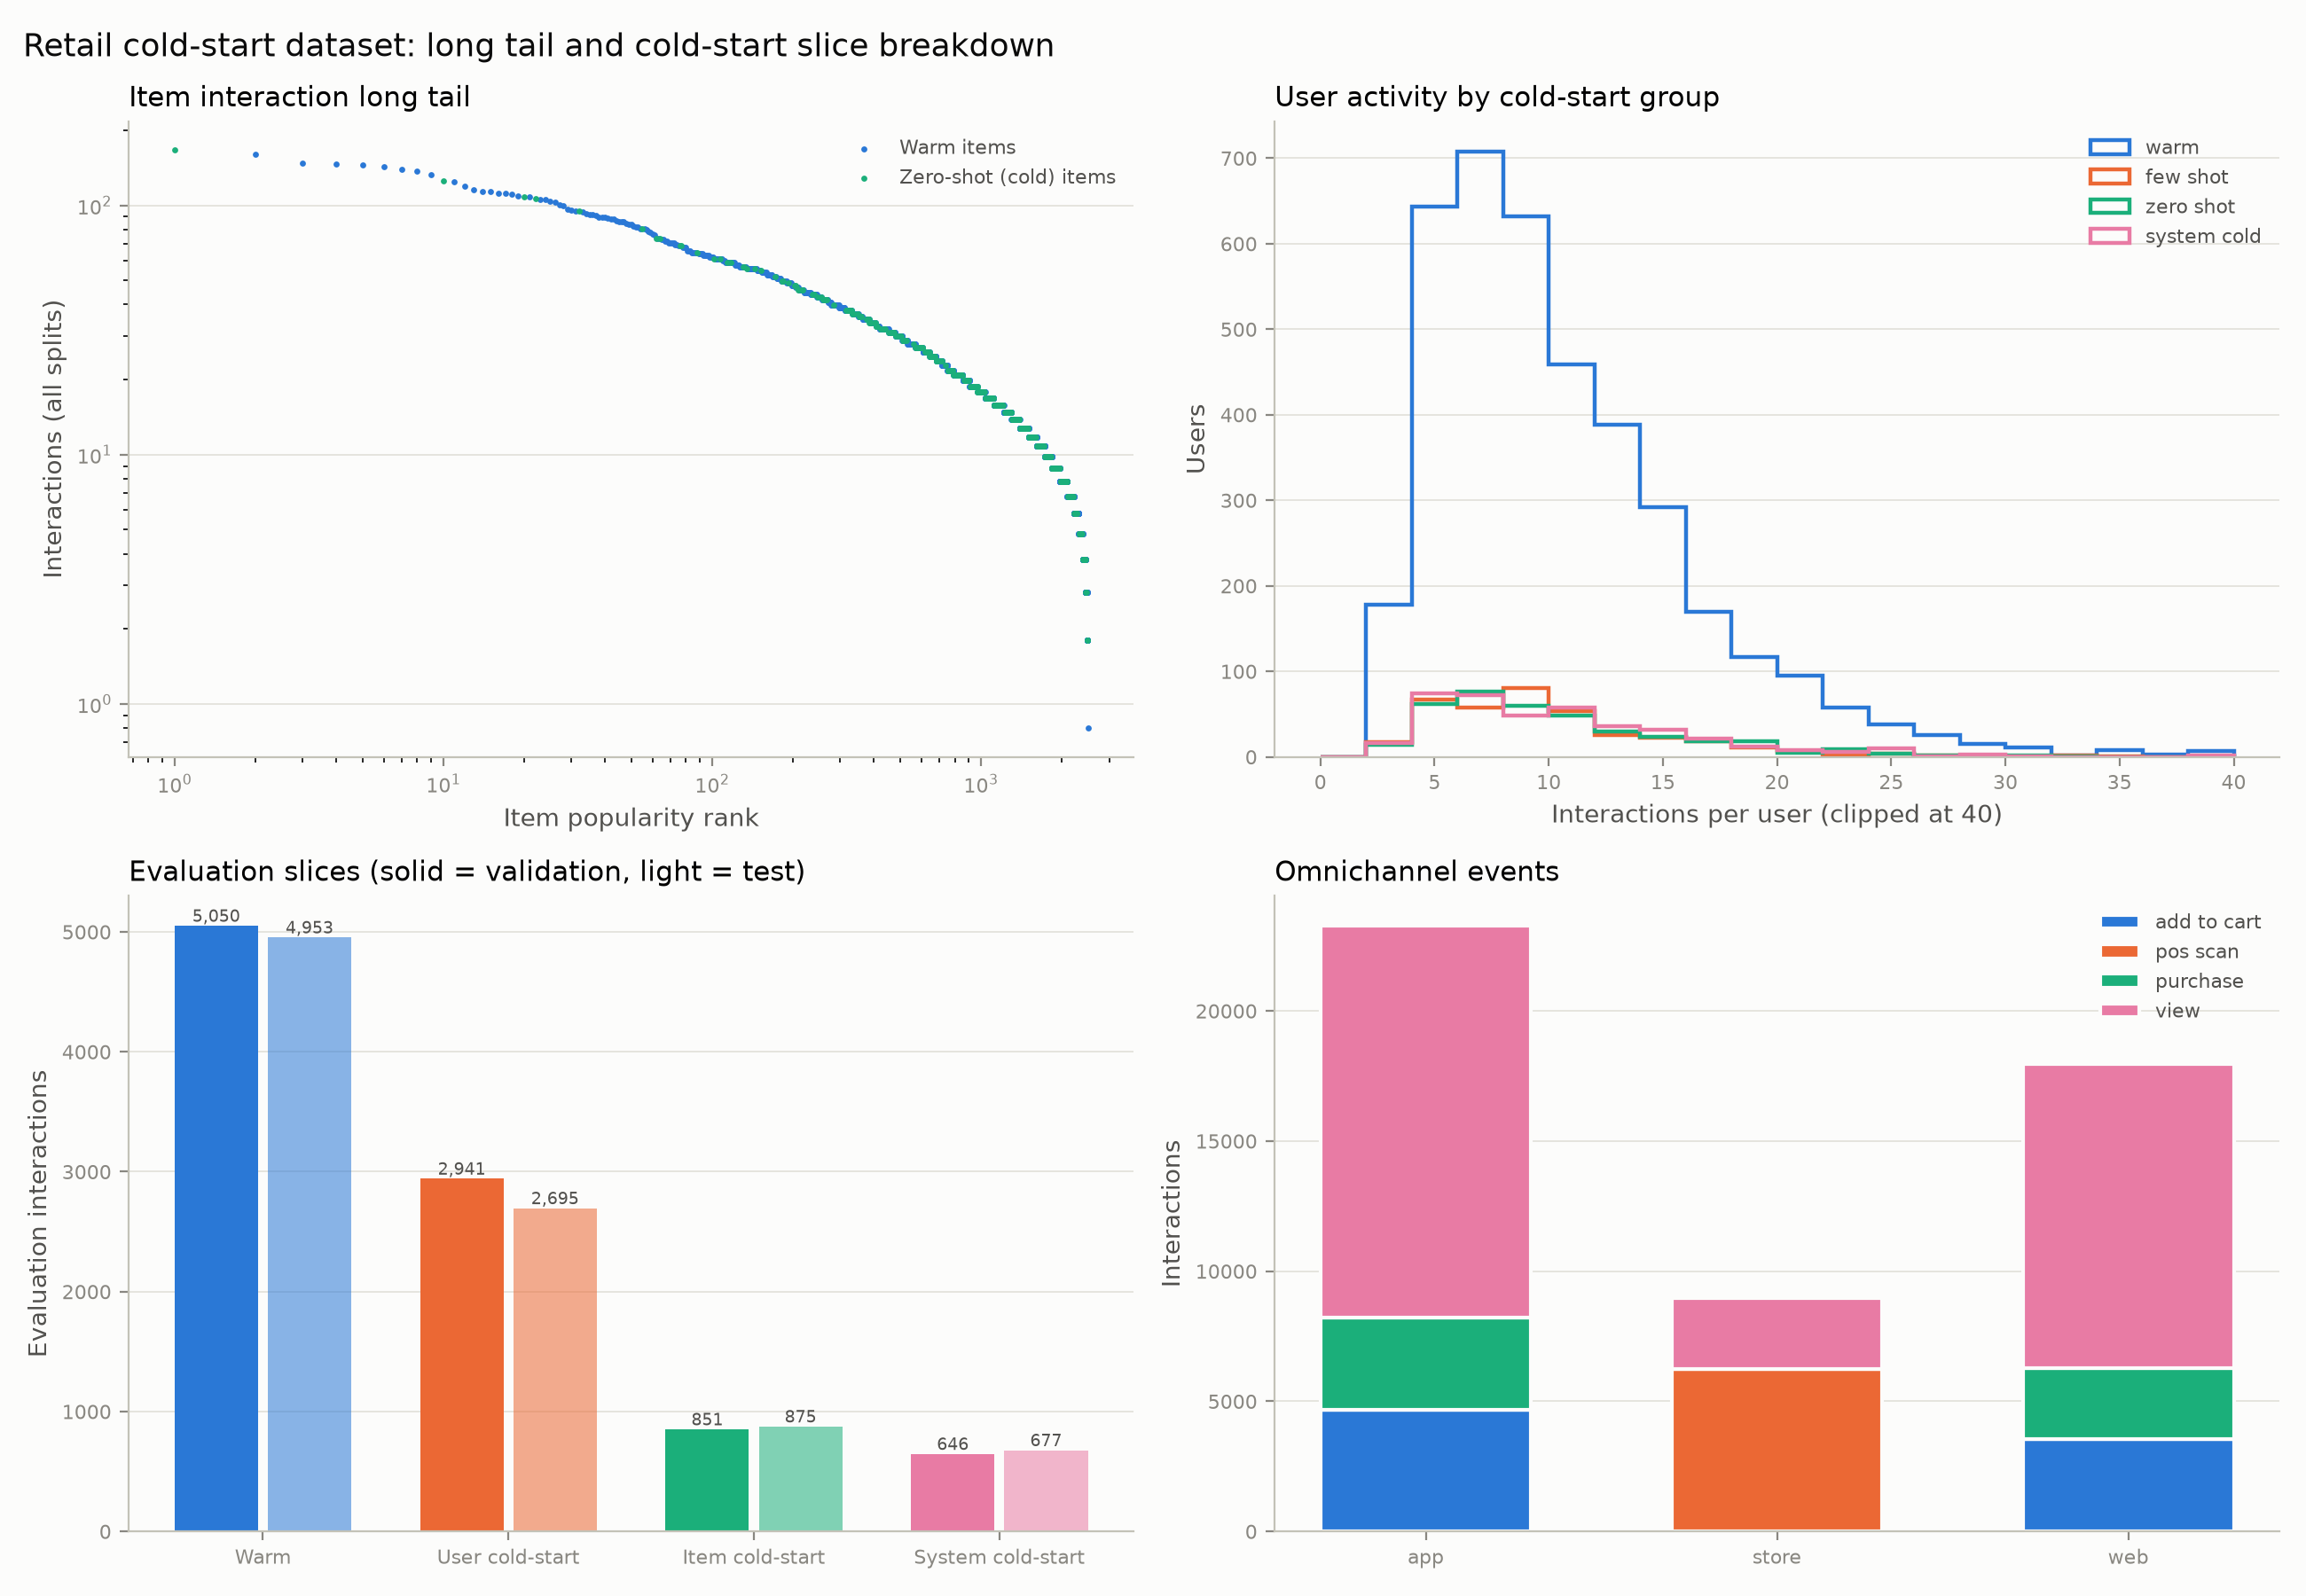

In [18]:
plot_eda(bundle.items, bundle.users, bundle.inter, manifest, OUT / "charts" / "01_eda_coldstart_distributions.png")
display(Image(str(OUT / "charts" / "01_eda_coldstart_distributions.png")))

## 18. Train Approach 1 - Multimodal two-tower

In [19]:
tcfg = cfg["train"]; histories = {}
with log.stage("train_two_tower"):
    tt, histories["two_tower"] = train_two_tower(bundle, ep(tcfg["two_tower"]["epochs"]), log)
pd.DataFrame(histories["two_tower"]).tail(3)

[2026-11-19T18:17:56] [train_two_tower] start 


[2026-11-19T18:17:58] [two_tower] epoch epoch=1 train_loss=6.668143485454803 val_loss=6.810039949417114 tau=0.07022926956415176 seconds=1.1


[2026-11-19T18:17:59] [two_tower] epoch epoch=2 train_loss=6.493212567999008 val_loss=6.814969491958618 tau=0.07020486146211624 seconds=0.61


[2026-11-19T18:17:59] [two_tower] epoch epoch=3 train_loss=6.020916989509096 val_loss=6.377707290649414 tau=0.07039294391870499 seconds=0.66


[2026-11-19T18:18:00] [two_tower] epoch epoch=4 train_loss=5.510372943066536 val_loss=6.197335243225098 tau=0.07136151194572449 seconds=0.61


[2026-11-19T18:18:00] [two_tower] epoch epoch=5 train_loss=5.351906472064079 val_loss=6.206207036972046 tau=0.07260870933532715 seconds=0.63


... (18 outputs left out)

[2026-11-19T18:18:12] [two_tower] epoch epoch=24 train_loss=4.213921617954336 val_loss=6.577837991714477 tau=0.07034125924110413 seconds=0.62


[2026-11-19T18:18:13] [two_tower] epoch epoch=25 train_loss=4.202524631581408 val_loss=6.579332637786865 tau=0.07031664252281189 seconds=0.62


[2026-11-19T18:18:13] [train_two_tower] end seconds=16.85


,epoch,train_loss,val_loss,tau,seconds
22,23,4.234210,6.561889,0.070508,0.62
23,24,4.213922,6.577838,0.070341,0.62
24,25,4.202525,6.579333,0.070317,0.62


## 19. Train Approach 2 - Inductive heterogeneous GraphSAGE

Also demonstrates inductive inference: a brand-new item / user is embedded from attribute neighbours only (no retraining).

In [20]:
with log.stage("train_graphsage"):
    gm, graph, histories["graphsage"] = train_graphsage(bundle, ep(tcfg["graphsage"]["epochs"]), log)
display(pd.DataFrame(histories["graphsage"]).tail(3))
Zu, Zi, states = gm.all_embeddings(bundle.ft)
ci = int(np.where(bundle.feats.item_cold)[0][0]); r = bundle.items.iloc[ci]
z = gm.embed_new_item(states, bundle.ft.item_text[ci:ci+1], bundle.ft.item_vis[ci:ci+1], bundle.ft.item_cont[ci:ci+1],
                      r.brand, r.l3, r.l2, int(r.price_tier))
print("cold item rebuilt from (Brand, Category, PriceTier) only -> cosine with full-graph embedding:", float((z[0] * Zi[ci]).sum()))
uz = int(np.where(bundle.feats.user_group == "zero_shot")[0][0]); ur = bundle.users.iloc[uz]
zu = gm.embed_new_user(states, bundle.ft.user_cat[uz:uz+1], ur.home_store, ur.acquisition_channel, ur.quiz_tags.split("|"))
print("zero-shot user rebuilt from (Store, Channel, QuizTags) only -> cosine:", float((zu[0] * Zu[uz]).sum()))

[2026-11-19T18:18:13] [train_graphsage] start 


[2026-11-19T18:18:13] [graphsage] epoch epoch=1 train_loss=6.9560137228532275 val_loss=6.1173561096191404 seconds=0.36


[2026-11-19T18:18:13] [graphsage] epoch epoch=2 train_loss=6.337919473648071 val_loss=5.981098937988281 seconds=0.33


[2026-11-19T18:18:14] [graphsage] epoch epoch=3 train_loss=6.122853365811435 val_loss=6.036459112167359 seconds=0.35


[2026-11-19T18:18:14] [graphsage] epoch epoch=4 train_loss=5.981108860536055 val_loss=6.08066759109497 seconds=0.36


[2026-11-19T18:18:14] [graphsage] epoch epoch=5 train_loss=5.890280831943858 val_loss=6.085411596298218 seconds=0.33


... (34 outputs left out)

[2026-11-19T18:18:26] [graphsage] epoch epoch=40 train_loss=4.679622606797651 val_loss=6.405586242675781 seconds=0.34


[2026-11-19T18:18:26] [train_graphsage] end seconds=13.31


,epoch,train_loss,val_loss,seconds
37,38,4.713247,6.401332,0.33
38,39,4.708391,6.441989,0.33
39,40,4.679623,6.405586,0.34


cold item rebuilt from (Brand, Category, PriceTier) only -> cosine with full-graph embedding: 1.0000001192092896
zero-shot user rebuilt from (Store, Channel, QuizTags) only -> cosine: 0.9999998807907104


## 20. Train Approach 3 - MAML few-shot user adapter

In [21]:
with log.stage("train_maml"):
    adapter, histories["maml"] = train_maml(bundle, tt, ep(tcfg["maml"]["epochs"]), log)
hm = pd.DataFrame(histories["maml"]); print("validation NLL: prior only %.3f -> adapted %.3f" % (hm.val_loss_prior_only.iloc[-1], hm.val_loss.min()))
hm.tail(3)

[2026-11-19T18:18:26] [train_maml] start 


[2026-11-19T18:18:30] [maml] epoch epoch=1 train_loss=6.756193661689759 val_loss=6.831781387329102 val_loss_prior_only=7.056510925292969 alpha_mean=0.09472747892141342 seconds=0.57


[2026-11-19T18:18:31] [maml] epoch epoch=2 train_loss=6.531949710845947 val_loss=6.843722343444824 val_loss_prior_only=7.056510925292969 alpha_mean=0.0913299173116684 seconds=0.53


[2026-11-19T18:18:31] [maml] epoch epoch=3 train_loss=6.54949312210083 val_loss=6.789588928222656 val_loss_prior_only=7.056510925292969 alpha_mean=0.08776991069316864 seconds=0.51


[2026-11-19T18:18:32] [maml] epoch epoch=4 train_loss=6.506633949279785 val_loss=6.770967960357666 val_loss_prior_only=7.056510925292969 alpha_mean=0.08417695015668869 seconds=0.57


[2026-11-19T18:18:32] [maml] epoch epoch=5 train_loss=6.468289693196614 val_loss=6.7522687911987305 val_loss_prior_only=7.056510925292969 alpha_mean=0.08076208829879761 seconds=0.38


... (24 outputs left out)

[2026-11-19T18:18:42] [maml] epoch epoch=30 train_loss=6.1054631551106775 val_loss=6.633806228637695 val_loss_prior_only=7.056510925292969 alpha_mean=0.040293656289577484 seconds=0.38


[2026-11-19T18:18:42] [train_maml] end seconds=16.13


validation NLL: prior only 7.057 -> adapted 6.634


,epoch,train_loss,val_loss,val_loss_prior_only,alpha_mean,seconds
27,28,6.088929,6.678584,7.056511,0.041363,0.37
28,29,6.126625,6.653371,7.056511,0.040834,0.38
29,30,6.105463,6.633806,7.056511,0.040294,0.38


## 21. Train Approach 4 - Self-supervised contrastive pretraining

[2026-11-19T18:18:42] [train_ssl] start 


[2026-11-19T18:19:06] [ssl] epoch epoch=1 train_loss=7.154810481601292 val_loss=4.388337135314941 uniformity=-2.5581881999969482 mean_dim_std=0.07833025604486465 seconds=0.33


[2026-11-19T18:19:06] [ssl] epoch epoch=2 train_loss=5.835538228352864 val_loss=4.010693550109863 uniformity=-2.8404042720794678 mean_dim_std=0.08270993828773499 seconds=0.18

[2026-11-19T18:19:07] [ssl] epoch epoch=3 train_loss=5.333422554863824 val_loss=3.7770540714263916 uniformity=-2.9232776165008545 mean_dim_std=0.08337718993425369 seconds=0.17


[2026-11-19T18:19:07] [ssl] epoch epoch=4 train_loss=5.024354033999973 val_loss=3.639401912689209 uniformity=-2.9874463081359863 mean_dim_std=0.08434280753135681 seconds=0.18

[2026-11-19T18:19:07] [ssl] epoch epoch=5 train_loss=4.793873945871989 val_loss=3.5357205867767334 uniformity=-2.9722068309783936 mean_dim_std=0.08380740880966187 seconds=0.18


... (33 outputs left out)

[2026-11-19T18:19:14] [ssl] epoch epoch=39 train_loss=3.125030517578125 val_loss=3.5240676403045654 uniformity=-3.1085238456726074 mean_dim_std=0.0831538587808609 seconds=0.28


[2026-11-19T18:19:15] [ssl] epoch epoch=40 train_loss=3.110601133770413 val_loss=3.5438640117645264 uniformity=-3.093413829803467 mean_dim_std=0.08293791115283966 seconds=0.25


[2026-11-19T18:19:15] [train_ssl] end seconds=32.59


,epoch,train_loss,val_loss,uniformity,mean_dim_std,seconds
37,38,3.144602,3.509248,-3.112625,0.083235,0.21
38,39,3.125031,3.524068,-3.108524,0.083154,0.28
39,40,3.110601,3.543864,-3.093414,0.082938,0.25


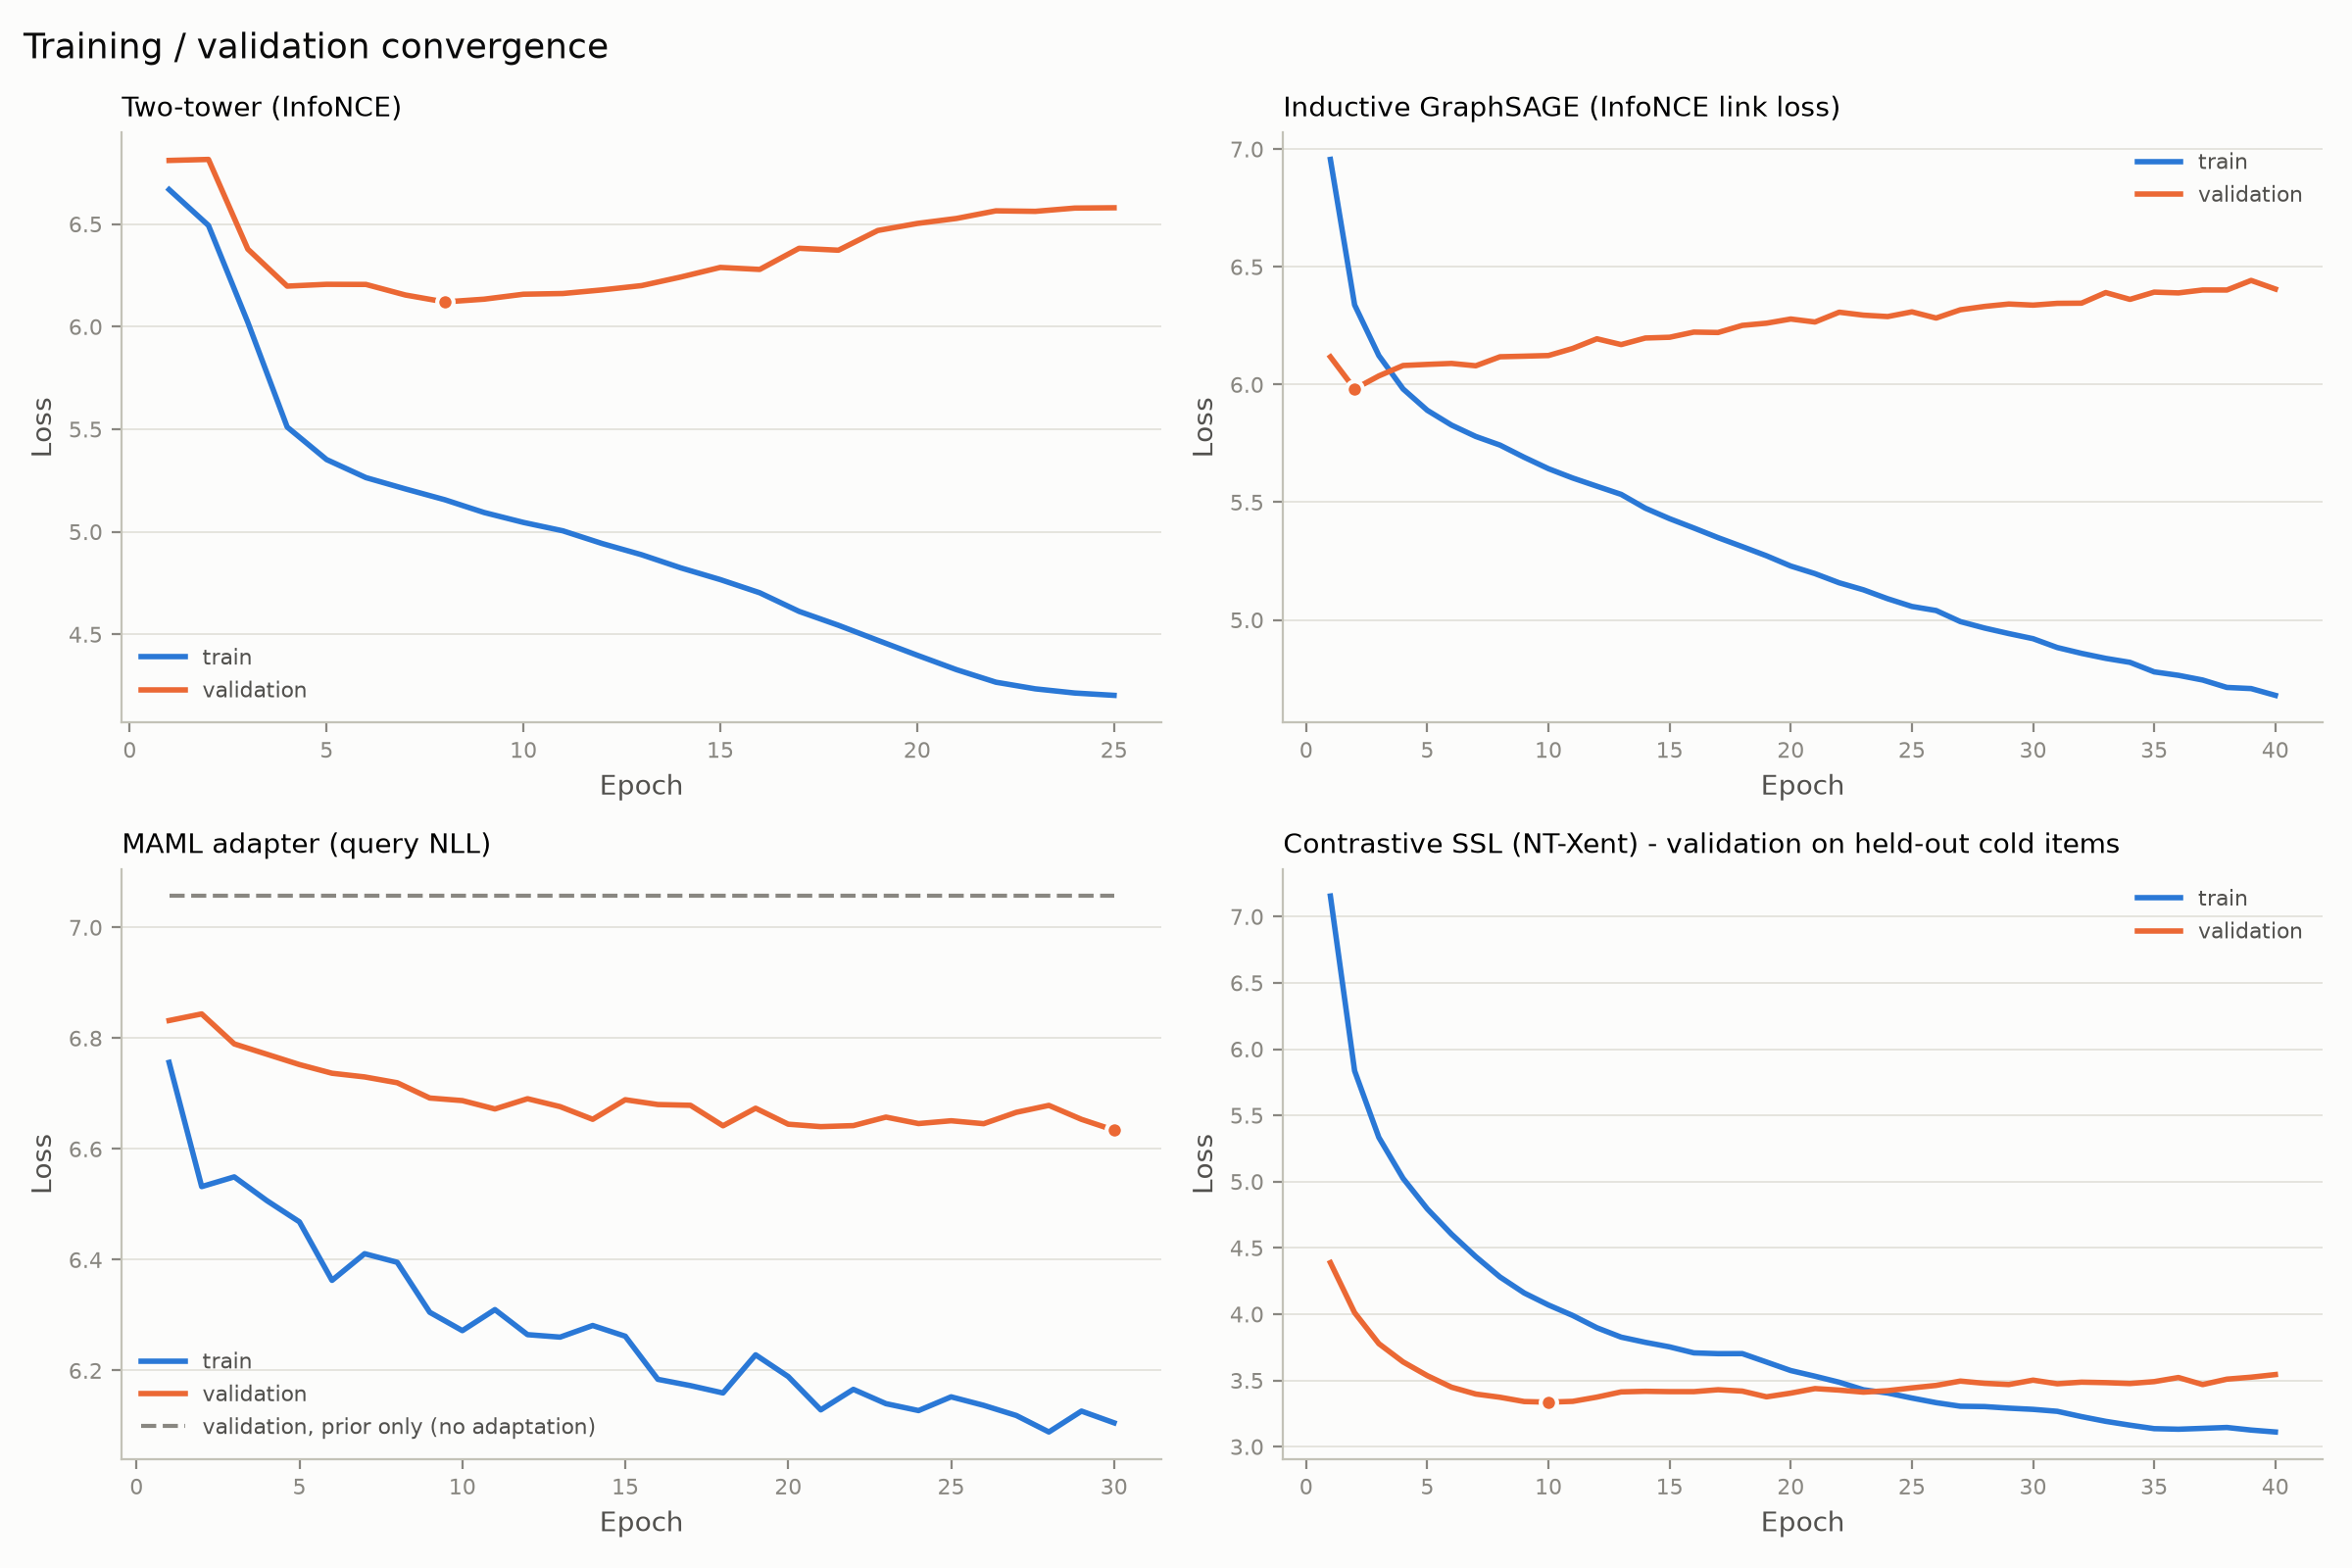

In [22]:
with log.stage("train_ssl"):
    ssl, histories["ssl"] = train_ssl(bundle, ep(tcfg["ssl"]["epochs"]), log)
display(pd.DataFrame(histories["ssl"]).tail(3))
json.dump(histories, open(OUT / "metrics" / "training_history.json", "w"), indent=2)
pd.DataFrame([{"model": m, **r} for m, hh in histories.items() for r in hh]).to_csv(OUT / "metrics" / "training_history.csv", index=False)
plot_loss_curves(histories, OUT / "charts" / "02_training_validation_loss_curves.png")
display(Image(str(OUT / "charts" / "02_training_validation_loss_curves.png")))

## 22. Unified representation hub: alignment, router and validation-only weight tuning

In [23]:
hub = RepresentationHub(bundle, tt, gm, graph, adapter, ssl)
cold_mask = torch.as_tensor(bundle.feats.item_cold, device=dev)
val_sets = build_eval_sets(bundle, bundle.val_df, cfg["eval"]["max_users_per_slice"], seed=1)
test_sets = build_eval_sets(bundle, bundle.test_df, cfg["eval"]["max_users_per_slice"], seed=2)
with log.stage("fusion"):
    hub.tune(val_sets, cold_mask, log)
save_all(OUT / "models", bundle, tt, gm, adapter, ssl, hub.w)
np.save(OUT / "models" / "unified_item_embeddings.npy", hub.E_uni.cpu().numpy())
print(json.dumps(hub.w, indent=2)); print({k: len(v) for k, v in test_sets.items()}, "test users per slice")

[2026-11-19T18:19:16] [fusion] start 


[2026-11-19T18:19:17] [fusion] tuned_route route=0 val_score=0.2032


[2026-11-19T18:19:17] [fusion] tuned_route route=1 val_score=0.2232


[2026-11-19T18:19:17] [fusion] tuned_route route=2 val_score=0.2115


[2026-11-19T18:19:17] [fusion] tuned_items 


[2026-11-19T18:19:17] [fusion] end seconds=1.9


{
  "item": {
    "c": 1.0,
    "g": 0.0,
    "s": 0.25
  },
  "r0": {
    "c": 1.0,
    "g": 0.5,
    "s": 0.0
  },
  "r1": {
    "m": 1.0,
    "g": 0.0,
    "s": 0.5
  },
  "r2": {
    "c": 1.0,
    "s": 0.5,
    "g": 0.0
  }
}
{'warm': 1500, 'user_cold': 707, 'item_cold': 751, 'system_cold': 315} test users per slice


## 23. FAISS indexing (exact IndexFlatIP vs IndexHNSWFlat vs IVF-PQ) and latency / recall benchmark

[2026-11-19T18:19:18] [ann_benchmark] start 


[2026-11-19T18:19:18] [ann_benchmark] end seconds=0.25


,index,recall@10_vs_exact,p50_ms,p95_ms,p99_ms,mean_ms,efSearch,nprobe
0,IndexFlatIP,1.0000,0.0275,0.0295,0.0331,0.0279,NaN,NaN
1,IndexHNSWFlat,0.8534,0.0079,0.0106,0.0128,0.0083,8.0,NaN
2,IndexHNSWFlat,0.9438,0.0104,0.0126,0.0146,0.0106,16.0,NaN
3,IndexHNSWFlat,0.9836,0.0153,0.0184,0.0228,0.0157,32.0,NaN
4,IndexHNSWFlat,0.9984,0.0260,0.0318,0.0475,0.0274,64.0,NaN
5,IndexHNSWFlat,1.0000,0.0538,0.0644,0.1005,0.0558,128.0,NaN
6,IndexHNSWFlat,1.0000,0.1315,0.1505,0.2207,0.1346,256.0,NaN
7,IndexIVFPQ,0.5912,0.0085,0.0102,0.0120,0.0088,NaN,1.0
8,IndexIVFPQ,0.6522,0.0105,0.0133,0.0301,0.0112,NaN,2.0
9,IndexIVFPQ,0.6660,0.0140,0.0177,0.0283,0.0142,NaN,4.0


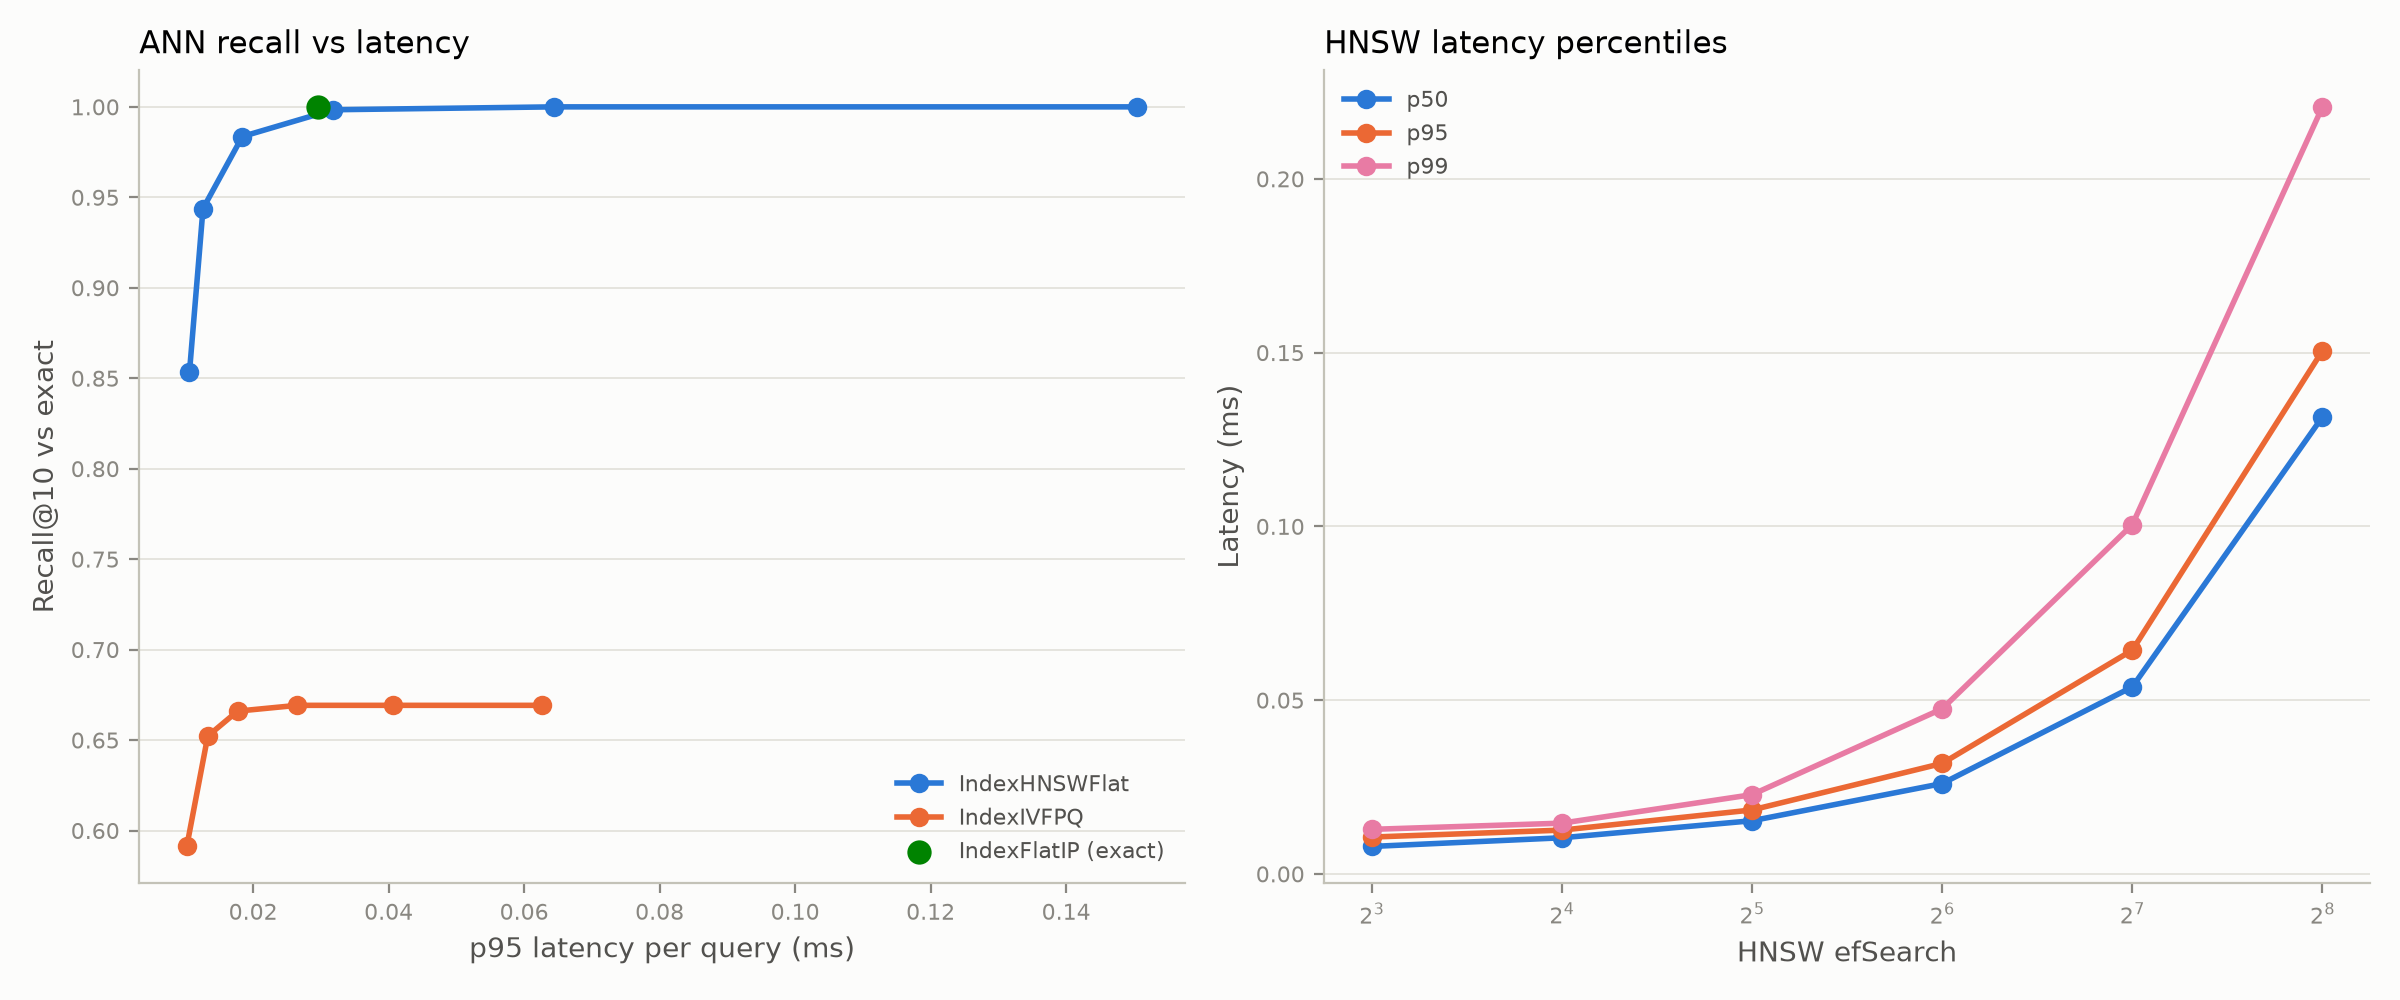

metadata-filtered (Footwear only) top-5: ['Sneakers', 'Sandals', 'Sneakers', 'Sneakers', 'Sneakers']


In [24]:
fc = cfg["faiss"]
fm = FaissManager(cfg["embedding_dim"]).build(hub.E_uni.cpu().numpy(), {"l1": bundle.items.l1.values}, fc["hnsw_m"], fc["ef_construction"],
                                              fc["ef_search"], (fc["ivfpq"]["nlist"], fc["ivfpq"]["m"], fc["ivfpq"]["nbits"]))
fm.save(OUT / "models")
qs = torch.cat([hub.unified_query(hub.raw_for_slice(sd), sd.nhist)[0] for sd in test_sets.values()])
qs = qs[torch.randperm(len(qs), generator=torch.Generator().manual_seed(0))[: fc["n_bench_queries"]].to(qs.device)].cpu().numpy()
with log.stage("ann_benchmark"):
    bench = fm.benchmark(qs, ef_sweep=fc["ef_search_sweep"], out_path=OUT / "metrics" / "ann_benchmark.json")
plot_ann_tradeoff(bench, OUT / "charts" / "05_ann_recall_latency.png")
display(pd.DataFrame(bench["results"]).round(4)); display(Image(str(OUT / "charts" / "05_ann_recall_latency.png")))
allowed = np.array([x == "Footwear" for x in bundle.items.l1]); D, I = fm.search(qs[:1], 5, "hnsw", allowed=allowed)
print("metadata-filtered (Footwear only) top-5:", [bundle.items.l3[i] for i in I[0]])

## 24. Stratified offline evaluation (test split): each approach vs the unified ensemble

[2026-11-19T18:19:18] [eval] start 


[2026-11-19T18:19:19] [eval] end seconds=0.65



== recall@10


slice,item_cold,system_cold,user_cold,warm
method,,,,
contrastive_ssl,0.058,0.040,0.035,0.064
inductive_graphsage,0.008,0.005,0.067,0.077
maml_user_adapter,0.042,0.014,0.068,0.107
popularity,0.000,0.000,0.016,0.013
two_tower_multimodal,0.047,0.014,0.071,0.095
unified_ensemble,0.058,0.023,0.074,0.099



== recall@20


slice,item_cold,system_cold,user_cold,warm
method,,,,
contrastive_ssl,0.123,0.086,0.073,0.117
inductive_graphsage,0.016,0.018,0.113,0.138
maml_user_adapter,0.089,0.045,0.114,0.159
popularity,0.000,0.000,0.024,0.027
two_tower_multimodal,0.101,0.045,0.120,0.152
unified_ensemble,0.112,0.050,0.121,0.166


... (8 outputs left out)


== alignment


slice,item_cold,system_cold,user_cold,warm
method,,,,
contrastive_ssl,0.932,1.129,1.096,0.942
inductive_graphsage,1.306,1.472,1.267,1.165
maml_user_adapter,1.502,1.705,1.581,1.474
popularity,NaN,NaN,NaN,NaN
two_tower_multimodal,1.447,1.705,1.557,1.424
unified_ensemble,1.135,1.564,1.384,1.114



embedding uniformity (items, lower = more uniform):


method
contrastive_ssl        -2.954
inductive_graphsage    -1.639
maml_user_adapter      -2.752
popularity                NaN
two_tower_multimodal   -2.748
unified_ensemble       -2.736
Name: uniformity_items, dtype: float64

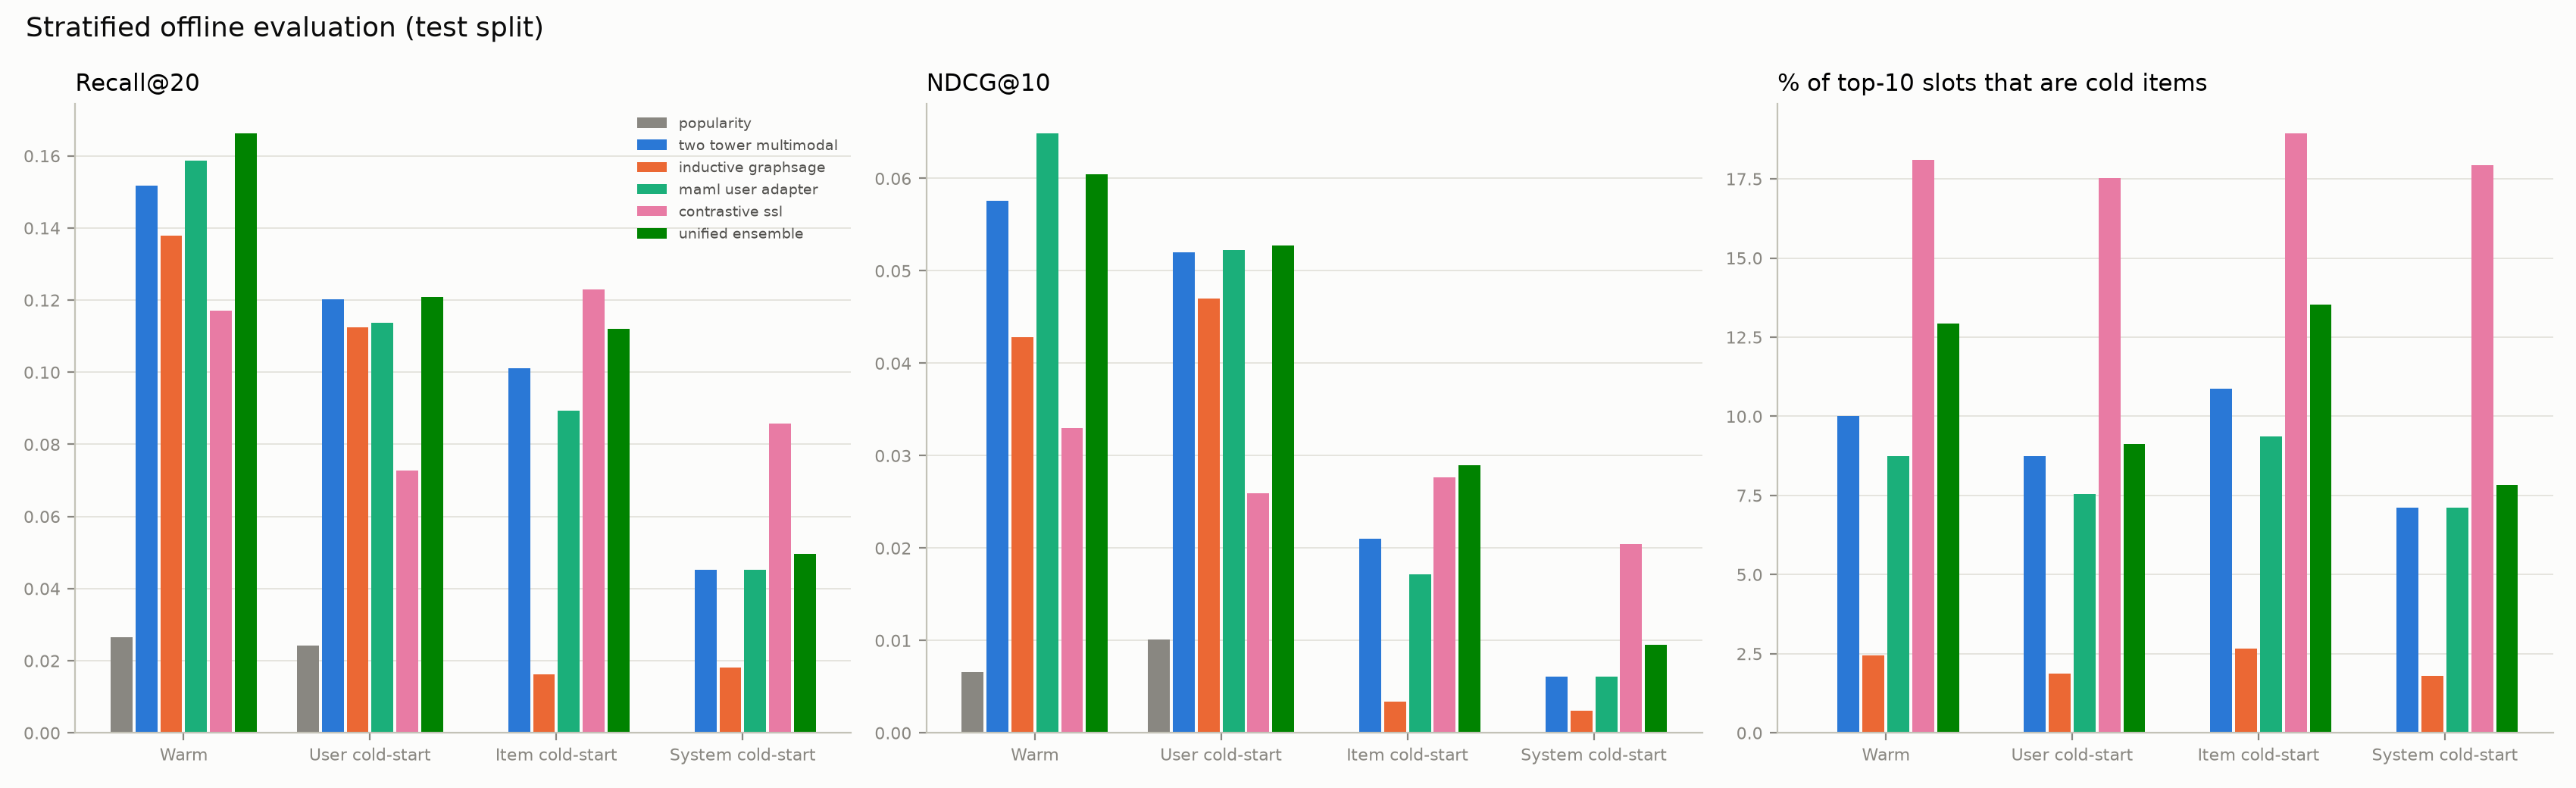

In [25]:
with log.stage("eval"):
    rows = []
    pop = torch.bincount(bundle.tr.i, minlength=bundle.n_items).float()
    rows += evaluate_method("popularity", None, None, test_sets, cold_mask, pop_scores=pop, ks=cfg["eval"]["ks"])
    for name, (qf, im) in hub.method_table().items():
        rows += evaluate_method(name, qf, im, test_sets, cold_mask, ks=cfg["eval"]["ks"])
    eval_df = save_metrics(rows, OUT / "metrics")
for m in ["recall@10", "recall@20", "ndcg@10", "mrr", "cold_items_recommended_pct", "catalog_coverage_pct", "alignment"]:
    print("\n==", m); display(eval_df.pivot(index="method", columns="slice", values=m).round(3))
print("\nembedding uniformity (items, lower = more uniform):"); display(eval_df.groupby("method").uniformity_items.first().round(3))
plot_slice_comparison(eval_df, OUT / "charts" / "04_coldstart_slice_comparison.png")
display(Image(str(OUT / "charts" / "04_coldstart_slice_comparison.png")))

## 25. Representation space projection (warm vs zero-shot items)

projection: t-SNE


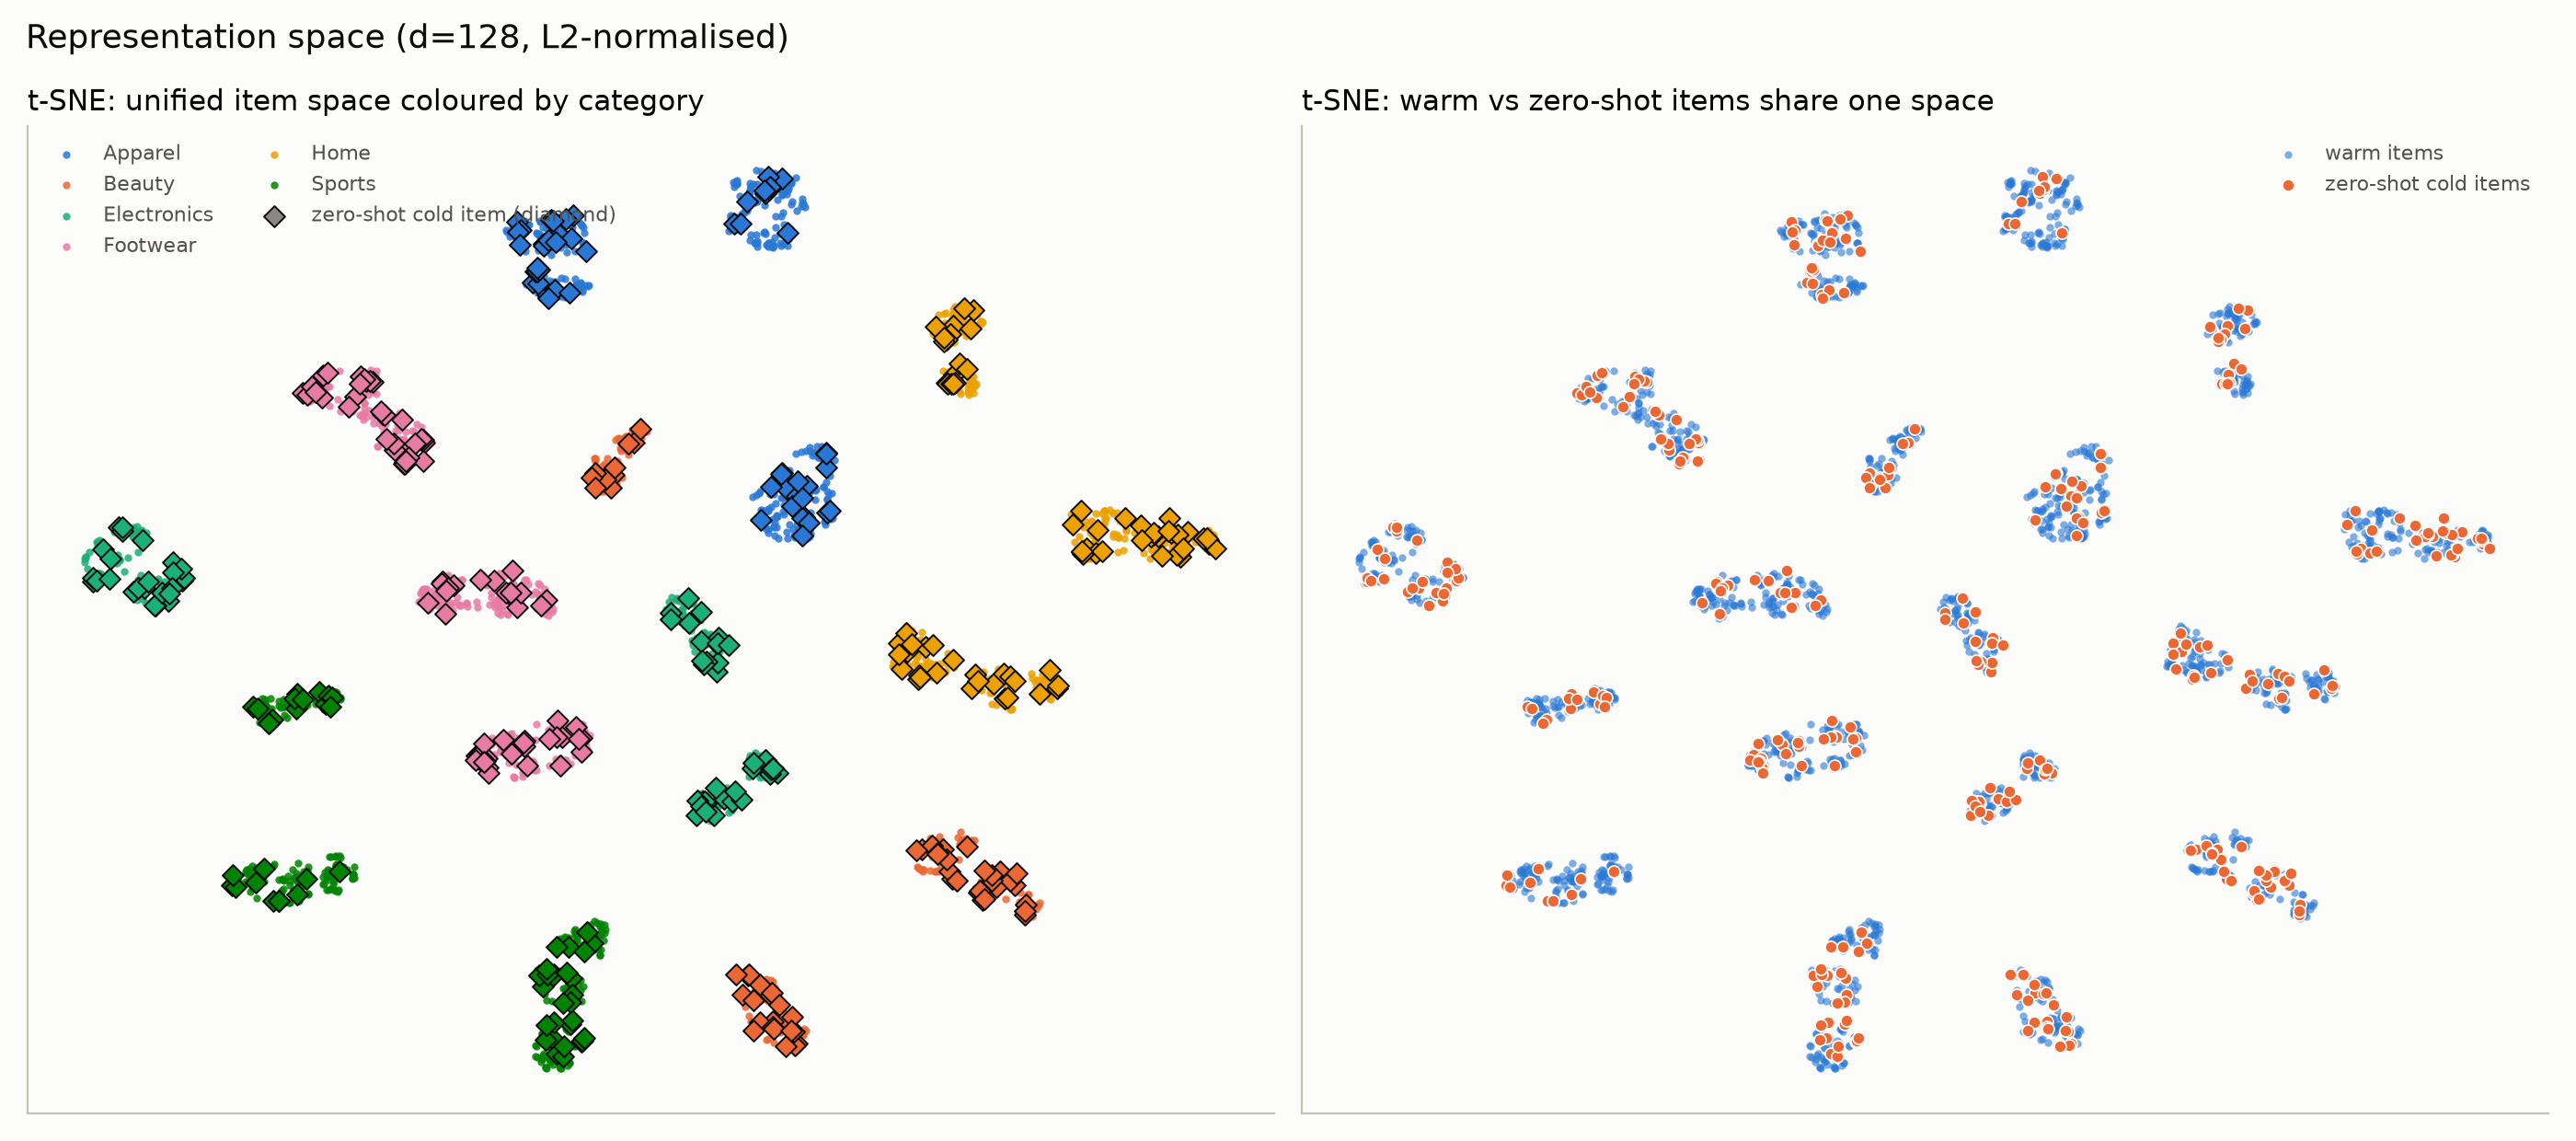

In [26]:
proj = plot_embedding_space(hub.E_uni.cpu().numpy(), bundle.items, OUT / "charts" / "03_representation_space_umap_tsne.png")
print("projection:", proj); display(Image(str(OUT / "charts" / "03_representation_space_umap_tsne.png")))

## 26. Router demo: recommendations by amount of user signal

In [27]:
def demo(label, uidx):
    hist = bundle.hist[uidx:uidx+1].clone()
    ctx = bundle.enc.transform_context([14], ["ios"], [bundle.users.home_store[uidx]], ["app"])
    raw = hub.raw_queries(bundle.ft.user_cat[uidx:uidx+1], bundle.ft.user_quiz[uidx:uidx+1], torch.as_tensor(ctx["cat"], device=dev),
                          torch.as_tensor(ctx["tod"], device=dev), hist, hub.Zu_g[uidx:uidx+1])
    n = (hist > 0).sum(1); q, route = hub.unified_query(raw, n)
    seen = set((hist[0][hist[0] > 0] - 1).tolist())
    D, I = fm.search(q.cpu().numpy(), 5, "hnsw", exclude=seen)
    print(f"{label:24s} quiz={bundle.users.quiz_tags[uidx]:38s} n_hist={int(n)} strategy={STRATEGIES[int(route[0])]}")
    print("   ->", [f"{bundle.items.l3[i]}{'*' if bundle.feats.item_cold[i] else ''}" for i in I[0]], "(* = zero-shot cold item)")
g = bundle.feats.user_group
demo("zero-shot user", int(np.where(g == "zero_shot")[0][0]))
demo("system-cold-store user", int(np.where(g == "system_cold")[0][0]))
demo("few-shot user", int(np.where(g == "few_shot")[0][0]))
demo("warm user", int(next(u for u in np.where(g == "warm")[0] if (bundle.hist_np[u] > 0).sum() > 3)))

zero-shot user           quiz=likes_haircare|likes_outdoor|likes_skincare n_hist=0 strategy=content+graph
   -> ['Water Bottles', 'Serums', 'Conditioner', 'Serums', 'Serums'] (* = zero-shot cold item)
system-cold-store user   quiz=cat_beauty|likes_haircare              n_hist=0 strategy=content+graph
   -> ['Conditioner', 'Conditioner', 'Conditioner', 'Conditioner', 'Shampoo'] (* = zero-shot cold item)
few-shot user            quiz=likes_audio|likes_haircare|likes_skincare n_hist=3 strategy=meta_adapter+graph
   -> ['Serums', 'Serums*', 'Sunscreen*', 'Sunscreen', 'Serums'] (* = zero-shot cold item)
warm user                quiz=likes_formal_shoes|likes_skincare|likes_team_sports n_hist=4 strategy=multimodal+contrastive_ensemble
   -> ['Oxfords*', 'Heels', 'Oxfords', 'Oxfords*', 'Oxfords'] (* = zero-shot cold item)


## 27. Sanity checks

In [28]:
ev = eval_df.set_index(["method", "slice"])
checks = {
    "zero leakage (manifest)": manifest["leakage_checks"] == "passed",
    "unified beats popularity on all 4 slices": all(ev.loc[("unified_ensemble", s), "recall@20"] > ev.loc[("popularity", s), "recall@20"] for s in SLICES),
    "item-cold unified recall@20 > 0.05": ev.loc[("unified_ensemble", "item_cold"), "recall@20"] > 0.05,
    "HNSW recall@10 >= 0.95 @ chosen efSearch": [r for r in bench["results"] if r["index"] == "IndexHNSWFlat" and r.get("efSearch") == fc["ef_search"]][0]["recall@10_vs_exact"] >= 0.95,
    "no embedding collapse (per-dim std > 0.01)": float(hub.E_uni.std(0).mean()) > 0.01,
    "MAML adaptation improves on prior": hm.val_loss.min() < hm.val_loss_prior_only.iloc[-1],
}
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)
assert all(checks.values())
log.log("notebook", "finished")

PASS - zero leakage (manifest)
PASS - unified beats popularity on all 4 slices
PASS - item-cold unified recall@20 > 0.05
PASS - HNSW recall@10 >= 0.95 @ chosen efSearch
PASS - no embedding collapse (per-dim std > 0.01)
PASS - MAML adaptation improves on prior
[2026-11-19T18:19:26] [notebook] finished 
